In [1]:
#%%capture
# @title ⚠️ Cargar configuración del cuaderno
# Cargamos módulos de análisis numérico
import numpy as np          # importamos numpy como np
import pandas as pd         # importamos pandas como pd
import math                 # importamos módulo para cáculos matemáticos
import random
import inspect
from scipy import stats
import matplotlib.colors as mcolors # Importamos matplotlib.colors

# Cargamos módulos de análisis gráficos
from plotnine import *      # importamos módulo para gráficos con ggplot
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
%config InlineBackend.figure_format = 'retina'


#===============================================
# Carga de datos desde GitHub
url = "https://raw.githubusercontent.com/UMH1477/python/refs/heads/main/data/datos_electrolinera_raw.csv"
df = pd.read_csv(url)

#===============================================
# Cargar funciones bloque1
from urllib.request import urlretrieve
import re # for text manipulation

url = 'https://raw.githubusercontent.com/UMH1477/python/refs/heads/main/bloque1_sps.py'
urlretrieve(url, "bloque1_sps.py")
import bloque1_sps
from bloque1_sps import *

# visualización de las funciones precargadas
functions = []
for name, obj in inspect.getmembers(bloque1_sps):
    if inspect.isfunction(obj) and obj.__module__ == bloque1_sps.__name__:
        functions.append(name)

print("\nFunciones precargadas en bloque1_sps.py:\n")
for func_name in functions:
    print(f"- {func_name}")

print("="*100)
print('''¡¡¡IMPORTANTE!!! Te recomendamos utilizar best_fit_discrete() y best_fit_continuous() para
ajustar distribuciones a datos discretos y continuos, respectivamente.''')


Funciones precargadas en bloque1_sps.py:

- MC_estim
- best_fit_continuous
- best_fit_continuous_v2
- best_fit_discrete
- calculate_chi2_robust
- cmtd_matrix_n
- distr_discreta
- gof_continuous
- graficar_discreta
- mat_ocupacion_proceso
- obtener_distribucion_ganadora
- simula_discreta
¡¡¡IMPORTANTE!!! Te recomendamos utilizar best_fit_discrete() y best_fit_continuous() para
ajustar distribuciones a datos discretos y continuos, respectivamente.


# ⚡ <font color="brown">**El "Hub" de Recarga Ibérico**</font>

El área de negocio de una empresa multinacional eléctrica dedicada al negocio de las electrolineras en autopistas, ha contratado consultoría al equipo de estrategia **VoltGrid Solutions**, para el que trabajas como analista de datos.

Desean analizar el funcionamiento de una nueva electrolinera gigante situada en la AP-7, y utilizar el estudio para diseñar su estrategia de expansión, dimensionando adecuadamente las electrolineras. Tu misión es diseñar un modelo robusto que permita evaluar la viabilidad técnica y económica de la red de electrolineras.


En concreto, desean que redactes un **Informe de Viabilidad Técnica y Económica** de acuerdo a las restricciones de funcionamiento, que te detallan a continuación, enfocado en la elaboración de procedimientos que les puedan ayudar a la toma de decisiones operativas fundamentadas en datos y simulación estocástica.

Dejaremos de ver los datos como fotos fijas del pasado para convertirlos en un **motor de predicción del futuro**. Utilizaremos Python, estadística avanzada y el poder de la Inteligencia Artificial para construir, paso a paso, un **Gemelo Digital (Digital Twin)** de nuestra infraestructura. Este simulador nos permitirá decidir si nuestro negocio es sostenible o si colapsará ante cambios en la demanda del mercado.


Tienen un interés particular en conocer:

1. **Cómo es el Mercado**, qué beneficios genera.

2. **Cuál es la magnitud de los beneficios netos generados** en función de la Potencia y Energía consumidas, así como del dimensionamiento de la infraestructura de conexión (transformador), para asumir picos de potencia y evitar desconexiones del sistema por sobrecarga y costes derivados.

3. **Recomendación de Inversión** en el alquiler de baterias para evitar cortes de servicio, dimensionamiento e impacto económico del alquiler.

Para realizar un análisis de viabilidad serio, debes comprender que una electrolinera no es solo un conjunto de enchufes; es un ecosistema donde la física de la red, el comportamiento del consumidor y la rentabilidad financiera colisionan.

## 📊 <font color="darkblue">**Estructura del banco de datos**</font>

Para realizar dicha tarea tu jefe te ha proporcionado un archivo [`datos_electrolinera_raw.csv`](https://raw.githubusercontent.com/UMH1477/python/refs/heads/main/data/datos_electrolinera_raw.csv) (en GitHub) con el registro real y consumos de todos los vehículos que han accedido a la electrolinera durante un periodo de 30 días completos.

Las características recogidas en la base de datos proporcionada por la empresa son:
* `Día`: identificador del día donde se produce la recarga.
* `Hora`: identificador de la hora en la que se produce la recarga.
* `Tipo_Franja`: Franja horaria en la que se produce la recarga.
* `Tipo_Vehículo`: Realmente alude al tipo de cargador utilizado.
* `Energia_kWh`: Energía cargada en la batería.
* `Potencia_kW`: Determina el valor máximo de recarga que admite la batería del vehículo.

**Los datos ya han sido cargados en la configuración del cuaderno. El dataframe se llama `df`. Prueba a visualizarlos con:**
```
display(df.sample(6))
```

## 🛠 <font color="darkblue">**Datos Técnicos y Económicos**</font>

Para tu análisis, debes tener en cuenta las siguientes restricciones operativas y de mercado (tanto en recursos como económicas):

### <font color="DarkCyan">**1. Infraestructura Eléctrica**</font>

**Potencia y Energía**. La potencia es similar al Ancho de Banda (Mbps) en internet, mientras que la energía es el equivalente al volumen de datos descargados (GB). Si intentas pasar 10 Gbps por un cable de 1 Gbps, el sistema falla instantáneamente, sin importar cuánto tiempo pase. Cada coche carga a una determinada potencia (velocidad) y luego almacena la energía que entra en función del tiempo que está cargando. Aclaremos estos conceptos:

| Concepto| Unidad| Definición| En el contexto de la electrolinera|
| --| --| --| --|
| Potencia (P)| kW / MW| Capacidad instantánea <br>de entrega.| La suma de lo que piden todos los coches a la vez (PIT). <br>Si PIT > límite del transformador, el sistema salta: <br> se produce una suspensión del suministro eléctrico.|
| Energía (E)| kWh / MWh| Cantidad total consumida<br> en un tiempo.| Lo que le facturas al cliente al final de la carga. <br> Energia = Potencia x tiempo.|
---

Otros parámetros del sistema son:

**Tiempo de Carga:** El tiempo que un vehículo pasa ocupando el cargador depende de la energía demandada y la potencia suministrada. Asumiendo una pérdida de eficiencia del 10% en el proceso de carga (calor, conversión) el tiempo de carga de un vehículo viene dado por.
   * `Tiempo (horas) = Energía (kWh) / (Potencia (kW) * 0.90)`.

**Límite del Transformador**: La limitación técnica más crítica de la instalación de este tipo de estaciones de recarga es la capacidad de acceso a la red. Aunque quisiéramos instalar 50 cargadores ultra-rápidos, estamos limitados por el Transformador que proporciona la energía a los vehículos.  Si la Potencia Instantánea Total (**PIT**) de los coches supera el límite del transformador, el interruptor automático (protección térmica) salta. Esto conlleva un daño reputacional severo y genera **costes operativos** (desplazamiento de técnicos, reinicio de sistemas).

**Costes operativos por corte eléctrico**. Los datos históricos de otras electrolíneras de la empresa muestran que el coste operativo de cada corte de suministro eléctrico por sobrecarga del transformador sigue una distribución Triangular con mínimo 1.500€, moda 2.000€ y máximo 3.500€.


**Baterías (BESS)**: Se está planteando alquilar un sistema de baterías para evitar la desconexión por picos (superamos el nivel del transformador). Cuando el software detecta que la PIT se acerca al límite, la batería empieza a descargar potencia para cubrir el exceso. En el modelo de alquiler o "Battery as a Service", se suele pagar una Cuota de Disponibilidad de kW/mes.


### <font color="DarkCyan">**2. Parque Vehicular y Afluencia**</font>

Puesto que se trata de una electrolinera de última generación, tiene **todos los tipos de surtidores disponibles en el mercado** para atender a cualquier vehículo, y además atiende toda la demanda que llega. No todos los coches demandan energía de la misma forma: los híbridos enchufables usan corriente alterna (AC) y otros, los eléctricos puros y los más potentes, corriente continua (DC). Hay actualmente 4 tipos de cargadores en función del tipo de vehículo, que se describen en la Tabla 1 junto con el parque vehicular asociado y la cuota de mercadado español.

> ⚠️ **Nota Importante:** En la **Tabla 1** se da además información sobre el uso de electrolineras en autopistas de peaje para cada tipo de vehículo. Por estos motivos, la cuota de mercado a nivel nacional **diferirá** de la afluencia específica de clientes en la electrolinera de la AP7.

<font size=2>***Tabla 1**: Parque vehicular español: cargador, cuota de mercado español, modelos de vehículos, y comportamiento en su afluencia a electrolineras de autopista.*</font>
| Vehículo | Cargador | Cuota de <br>mercado <br> (España) | Afluencia electrolinera AP7 |
| :--- | :--- | :---: | :--- |
| **PHEV + Motos + City Cars:**<br>Lynk & Co 01, Jeep Compass 4xe, <br>Renault Zoe, Dacia Spring. | **1. AC / Lentos** <br>(Tipo 2) | **30%** | **Baja afluencia.** <br>Los PHEV usan gasolina en viajes largos.<br>Solo paran si van a comer y aprovechan <br>("carga de oportunidad"). |
| **El "Grueso" del Parque (400V):**<br>Hyundai Kona (gen1), Kia e-Niro, <br>Peugeot e-2008/e-208, <br> Citroën ë-C4, Nissan Leaf. | **2. DC Estándar** <br>(50-100 kW) | **40%** | **Usuarios habituales.** <br>Tienen autonomías de 300-400km. <br>Necesitan parar sí o sí. <br>Ralentizan la carga cuando <br> la  batería llega al 80%.|
| **Los "Reyes" de la Ruta (400V Eficiente):**<br>Tesla Model 3 / Model Y (Líder absoluto), <br>VW ID.4, Skoda Enyaq, Volvo EX30. | **3. HPC Mainstream**<br> (150 kW) | **20%** | **Alta frecuencia.**<br> Tesla domina las ventas de BEV puros. <br>Cargan muy rápido y liberan el poste pronto. |
| **Arquitectura 800V / Lujo:**<br>Hyundai Ioniq 5, Kia EV6, Porsche Taycan,<br> Audi e-Tron GT, Tesla Model S/X Plaid. | **4. HPC Premium** <br>(>250 kW) | **10%** | **Nicho tecnológico.**<br> Cargan a potencias brutales (>200kW). <br>Son los que generan los picos <br>peligrosos de demanda. |
---

### <font color="DarkCyan">**3. Estructura de Ingresos y Costes**</font>

La rentabilidad de la electrolinera depende del margen de ventas, esto es, de la diferencia entre el precio de venta y el coste de adquisición de la energía.

* **Coste de la energía:** La electrolinera compra la energía a la red a un coste fijo promedio de **0.20 € / kWh** (incluyendo peajes y cargos). Esto la protege de la volatilidad del mercado diario, y le permite hacer proyecciones estables.

* **Tarifas de Venta (PVP):** La empresa aplica una tarifa distinta al cliente según la velocidad de carga (tipo de cargador):
    * **1. AC/PHEV:** 0.30 € / kWh
    * **2. DC Estándar:** 0.40 € / kWh
    * **3. HPC 150:** 0.60 € / kWh
    * **4. HPC 350:** 0.75 € / kWh

* **Beneficio Bruto:** El beneficio bruto por vehículo ($BB$ en euros) se puede obtener a partir de la energía consumida por el vehículo ($E$ en kWh), la tarifa de venta de la energía por parte de la electrolínera ($TV$ en euros), y el coste de la energía o tarifa de pago de la electrolínera ($CE$ en euros) como:

$$BB = E*(TV-CE)$$

* Para conseguir el **beneficio neto** ($BN$ en euros) se deberán sustraer del beficio bruto los costes operativos por penalizaciones del servicio ($COP$ en euros), es decir:

$$BN = BB - COP$$


### <font color="DarkCyan">**4. Perfil de Tráfico Diario**</font>

La AP7 es una arteria vital. El flujo de vehículos sigue patrones humanos (sueño, hambre, jornada laboral). Por tanto la afluencia de vehículos no es constante. Podemos distinguir hasta seis franjas de afluencia, que se detallan con sus horarios en la Tabla 2.

* **Franjas VALLE**: Tráfico Residual en dos franjas: Noche y Cierre. Principalmente logística nocturna (camiones), servicios de urgencia y viajeros esporádicos. La estación está prácticamente vacía.

* **Franjas LLANO**: Tráfico fluido en dos franjas: Mañana y Tarde. Es el escenario ideal donde el transformador trabaja cómodamente y el beneficio es constante. Desplazamientos laborales y tramos intermedios de viajes largos. Hay flujo constante de entrada y salida, pero sin aglomeraciones.

* **Franjas PUNTA**: Tráfico denso en dos franjas: Mediodía y Retorno y . Coincidencia masiva de paradas biológicas (comer/cenar) y retorno de trabajo o vacacional. Es el momento donde se producen los picos de potencia peligrosos.

<font size=2>***Tabla 2**: Franjas de afluencia de clientes a la electrolinera y horarios.*</font>
| <font size=3>Franja </font>|<font size=3>Horario</font>|
| :--- |:--- |
| <font size=3>Valle-Cierre</font> |<font size=3> 23:00 a 00:00</font>|
| <font size=3>Valle-Noche</font> |<font size=3>00:00 a 07:00</font>|
| <font size=3>Llano-Mañana</font> |<font size=3>07:00 a 11:00 |
| <font size=3>Llano-Tarde</font> |<font size=3>15:00 a 18:00</font>|
| <font size=3>Punta-Mediodía</font> |<font size=3>11:00 a 15:00 </font>|
| <font size=3>Punta-Retorno</font> | <font size=3>18:00 a 23:00</font> |

> ⚠️ **Nota Importante:** Se cree que la flota de vehículos (por tipo de cargador) de los clientes de la electrolinera es estable en todas las franjas horarias. Convendrá no obstante, verificarlo. Ya se comentó que se espera una cuota de mercado diferente a la nacional.

# 🛣️ Nuestra Hoja de Ruta: Del Dato a la Decisión

A lo largo de este proyecto, completarás los siguientes hitos clave:

### 1️⃣ El Latido del Mercado: Modelización de Llegadas
Todo empieza con el flujo de clientes. Analizaremos los datos históricos para entender cómo llegan los vehículos según la franja horaria. Aprenderás a modelizar la incertidumbre de las llegadas y crearás el **primer motor de nuestro simulador**, capaz de generar escenarios de afluencia realistas por hora.

### 2️⃣ El ADN del Cliente: Mixtura de Vehículos
No todos los coches son iguales: un híbrido enchufable (PHEV) no demanda lo mismo que un Tesla de carga ultra-rápida. Estimaremos las cuotas de mercado actuales y utilizaremos **mixturas de distribuciones** para que nuestro simulador asigne una "identidad" (tipo de vehículo) a cada coche que entra en la estación.

### 3️⃣ Energía, Potencia y la Caja Registradora
¿Cuánta energía demanda cada coche? ¿A qué potencia carga? Aquí aplicaremos **transformaciones de variables aleatorias** y el **método de composición** para vincular cada vehículo con su consumo específico. Al final de este hito, calcularemos el **beneficio bruto** por cada repostaje.

### 4️⃣ Gestión del Riesgo y Resiliencia (Transformador vs. Batería)

Nuestra estación de carga ha crecido con éxito, pero ahora nos enfrentamos a un límite físico crítico: la potencia máxima que puede suministrar nuestro **transformador de red** (Capacidad Nominal). Si en una hora determinada la demanda acumulada de los vehículos supera este límite, el sistema colapsa, provocando cortes de suministro, mala imagen y penalizaciones económicas. En este reto, diagnosticaremos la salud de nuestra infraestructura y evaluaremos si es mejor ampliar el transformador o instalar un **Sistema de Almacenamiento de Energía por Baterías (BESS)**.

---

> **🛠️ Tu Caja de Herramientas:**
> * **Python** para la orquestación del código.
> * **Scipy.stats** para la modelización de la incertidumbre.
> * **Gemini / GPT** como tu consultor experto en algoritmia y pensamiento crítico.
>* **Tu conocimiento como experto en analítica de datos** y reconocimiento de patrones.
> * Las funciones precargadas en el fichero **bloque1_sps.py**, entre las que dispones del estimador Monte Carlo y otras para el ajuste de distribuciones discretas y continuas. Revisa el código para entender el funcionamiento, input y output, con:
```
print(inspect.getsource(nombre_funcion))
print(help(nombre_funcion))
```

📌 **NO OLVIDES EJECUTAR LA CONFIGURACIÓN DEL CUADERNO**

---

## 🎯 1. El Latido del Mercado (Modelización de Llegadas)

En cualquier negocio de servicios, el primer paso para la optimización es entender el **flujo de demanda**. No podemos gestionar una electrolinera si no sabemos cuántos coches esperar. En este objetivo, vamos a transformar los datos históricos en un **motor de simulación de llegadas**.

### **1.1. Análisis Exploratorio y Segmentación**
La demanda no es constante a lo largo del día. Dispones de un dataset con registros históricos. Tu primera misión es aislar el comportamiento de cada una de las franjas para estudiar cómo se comportan.


- **T1.1.1. Afluencia**. Filtra el dataframe original por franjas y calcula la afluencia por horas para cada día. Por cada franja representa la distribución de frecuencias del número de vehículos que llegan por hora. ¿Podrías afirmar que la tasa de llegadas se mantiene estable por franja a lo largo de los días? ¿Podrías asumir una tasa de llegadas única por franja-periodo?

- **T1.1.2. Habilidad IA**. Consulta a Gemini/GPT: *"En un contexto de tráfico de vehículos, ¿qué fenómenos reales pueden romper la hipótesis de independencia de una distribución de Poisson? ¿Qué significa que un proceso de llegada tenga 'memoria' o presente 'agrupamiento' (clustering)? ¿Qué alternativas a la Poisson hay y en qué circunstancias son plausibles?"*


---

### **1.2. Modelización Estocástica**
No queremos simplemente "repetir el pasado", queremos un modelo matemático que pueda generar "futuros posibles".

- **T1.2.1. Modelado.** La primera intuición, y la más simple, para modelar las llegadas es una distribución de Poisson. ¿Hay indicios para poder usarla? Ajusta una distribución de probabilidad a tus datos en cada franja.

>📌Con la función `modelos = best_fit_discrete(data)` ajusta las distribuciones alternativas para modelizar el número de llegadas. La función `obtener_distribucion_ganadora(modelos)` toma el mejor modelo obtenido con `best_fit_discrete(data)` y nos proporciona la distribución en formato stats.scipy, que podremos usar directamente en nuestro simulador. Si tenemos que modelar las seis franjas horarias, obtenderemos seis distribuciones distintas. Para gestionar todas las franjas en nuestro simulador podemos definir un diccionario con keys las franjas y con valores la distribución que devuelve la función anterior para cada una de ellas.

La distribución para el conjunto de datos 'Valle (Noche)' se obtendría como:
```python
data # datos de 'Valle (Noche)'
modelos = best_fit_discrete(data)
distri = obtener_distribucion_ganadora(modelos)
```

Procediendo de forma similar con todas las franjas horarias puedes construir el diccioanrio de distribuciones con este aspecto:
```python
{'Valle (Noche)': distri,
 'Llano (Mañana)': #colocar aqui la distribución correspondiente para esta franja,
 'Punta (Mediodía)': #colocar aqui la distribución correspondiente para esta franja,
 'Llano (Tarde)': #colocar aqui la distribución correspondiente para esta franja,
 'Punta (Retorno)': #colocar aqui la distribución correspondiente para esta franja,
 'Valle (Cierre)': #colocar aqui la distribución correspondiente para esta franja}
```
que utilizaremos posteriormente en los algoritmos que debes desarrollar.

- **T1.2.2 Verificación**. Compara los valores teóricos de medias y varianzas con los de los datos históricos. Superpón una curva a cada histograma con la distribución ajustada para verificar que ajusta bien. Extrae conclusiones.

---

### **1.3. Construcción del Simulador (Algoritmia)**

- **T1.3.1. Algoritmia.** Escribe el algoritmo para simular las llegadas de vehículos por hora a la electrolinera.


- **T1.3.2. Programación.** Ahora programa el simulador para poder replicar cómo acontecen las llegadas a la estación. Sigue las indicaciones a continuación

```python
# Inicialización (variables globales)

N_DIAS = ... # Número de días (completos) a simular (entero)
MODELOS_LLEGADAS = ... # Diccionario con los modelos ajustados

def simular_nllegadas():
    """
    Genera una serie de llegadas aleatorias basadas en
    los modelos ajustados por franjas.
    
    Entrada (variables globales: externas):
      - N_DIAS(int), el número de días (completos) a simular
      - MODELOS_LLEGADAS (diccionario con distribuciones)
    
    Salida:
    - df_nllegadas : dataframe con el número total de coches que llegan en cada hora/franja/día.
    """
    # Tu código aquí
    return
```

- **T1.3.3. Estabilidad y Validación Monte Carlo**. Para confiar en nuestro simulador, debemos asegurar que sus resultados son estables. Genera una muestra de 100 dias usando tu función `simular_nllegadas`. Aproxima por Monte Carlo las medias y varianzas del número de llegadas en cada franja.
>¿El intervalo de confianza obtenido para la media incluye el valor promedio de tus datos históricos? ¿Y con el valor teórico de la distribución ajustada? Si repites la simulación con 1000 días, ¿qué ocurre con la amplitud del intervalo? Explica la relación entre el tamaño de la muestra simulada y la precisión de las estimaciones.

#### **1.4: Escenario de Estrategia "Stress Test".**

Imagina que el departamento de Marketing lanza una campaña agresiva y se prevé que la llegada media de vehículos aumente un **25%** en cualquier franja horaria.
* **T1.4.1. Habilidad IA:** Pregunta a la IA: *"Si mi proceso de llegadas sigue una distribución de Poisson($\lambda$), ¿cómo se calcula la probabilidad de exceder una capacidad $k$ si el parámetro $\lambda$ aumenta un 25%? Dame la fórmula o la lógica en Python."*
* **T1.4.2. Simulación:** Modifica las tasas de llegadas con dicho incremento en el simulador y calcula la probabilidad de que lleguen más de 50 vehículos en una hora (asumiendo que ese es el límite crítico de saturación).
* **T1.4.3. Reflexión:** Basándote en el resultado, ¿recomendarías lanzar la campaña de marketing ahora o sugerirías ampliar la infraestructura primero? Justifica tu decisión con los datos obtenidos.


## SOLUCIONES

Incorpora a continuación la solución a las tareas. Debes incluir todo el código utilizado claramente explicado y organizado para cada tarea.


## 1.1 Análisis exploratorio y segmentación

### T1.1.1. Afluencia

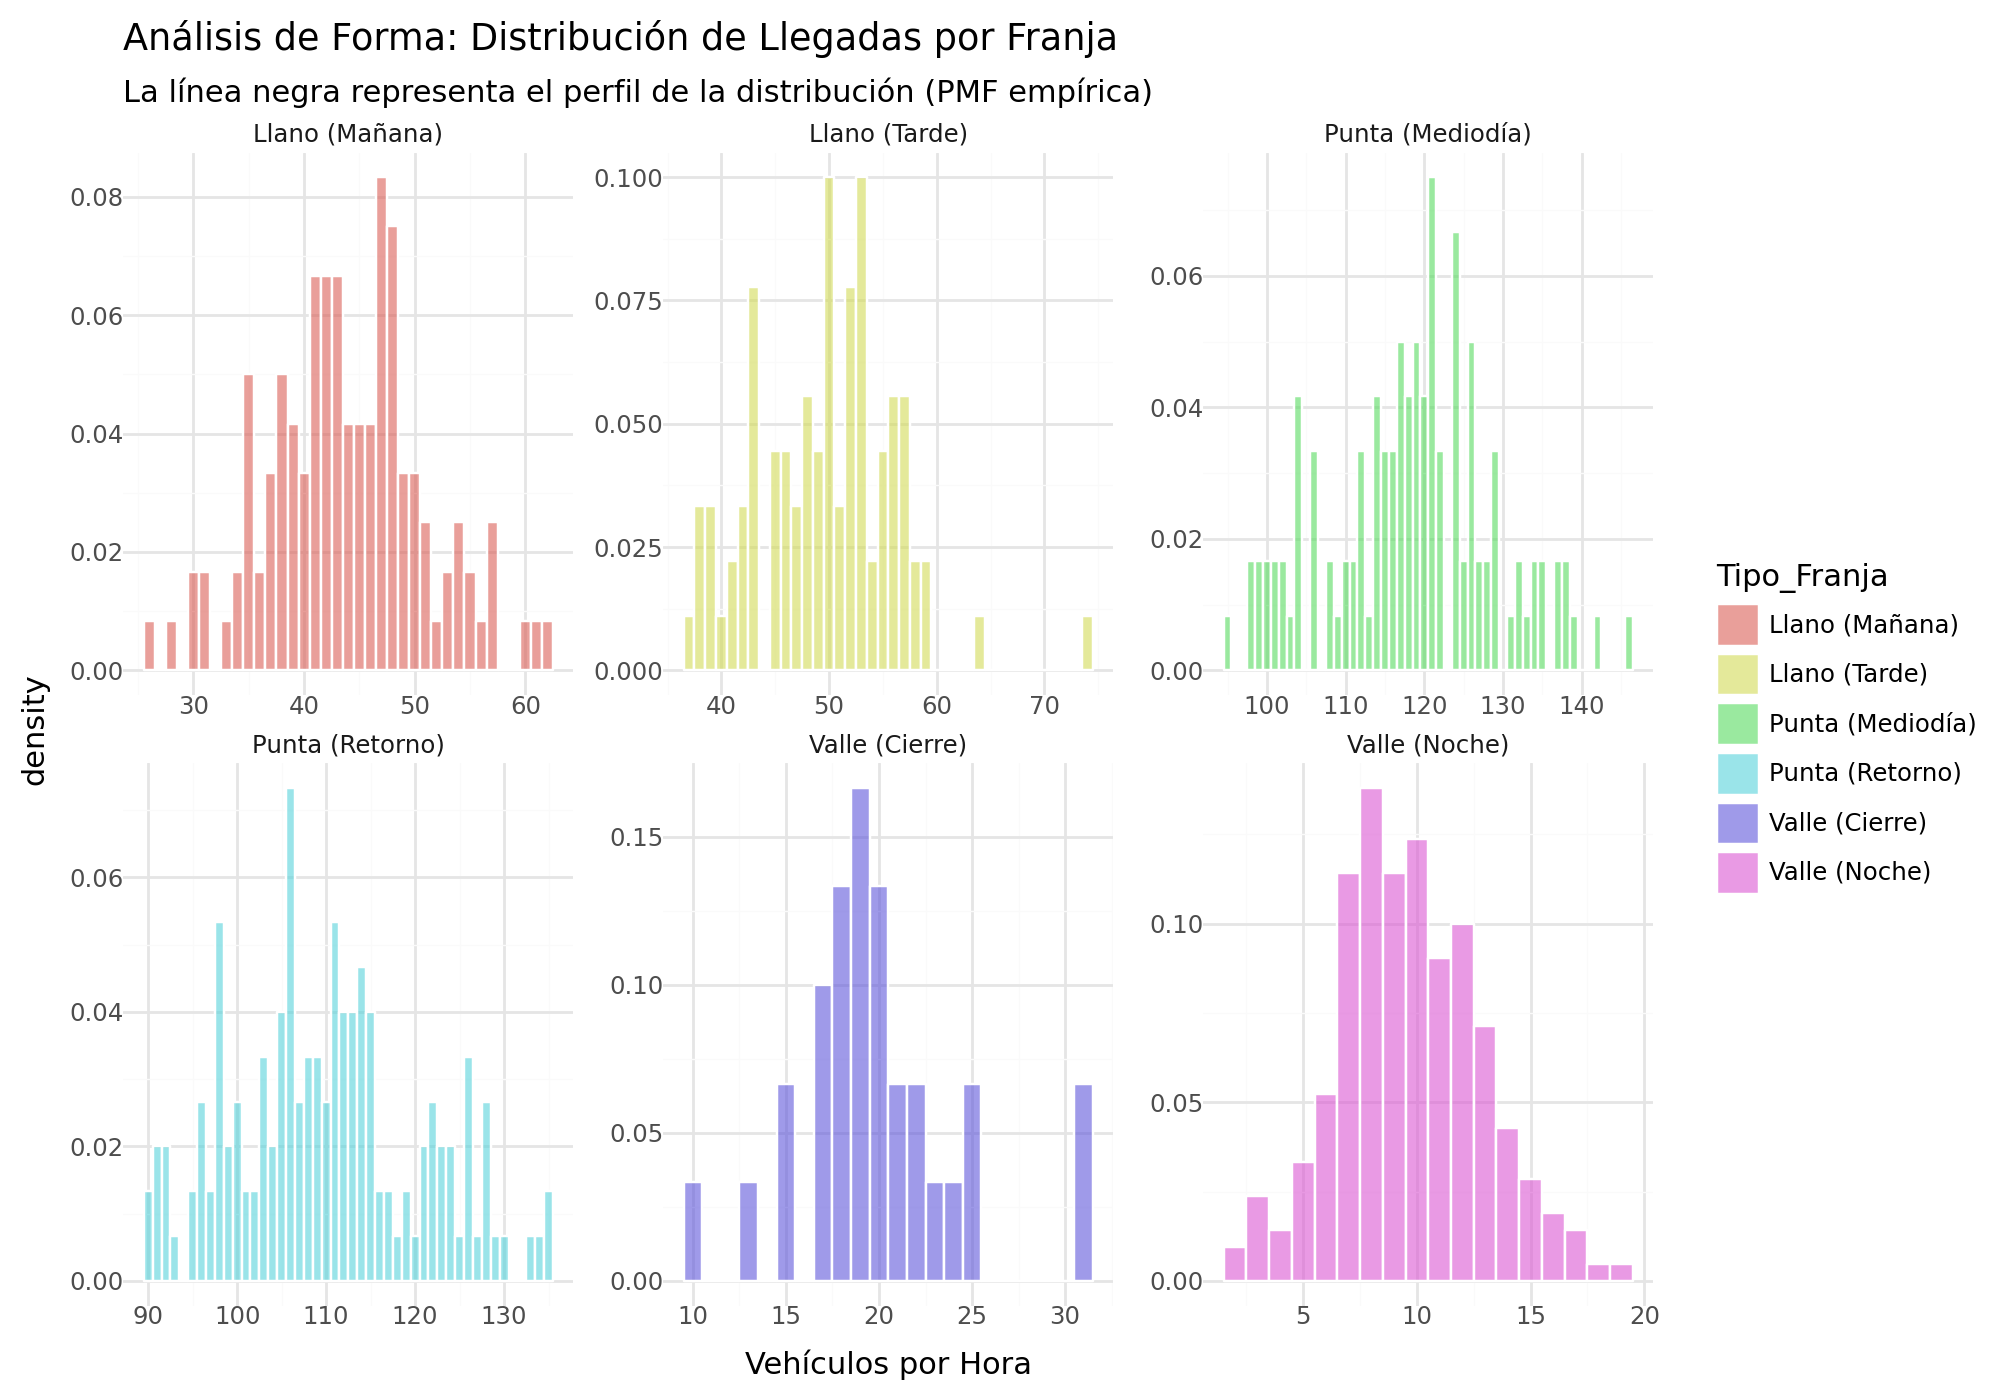

In [2]:
# 1. Preparacion de los datos: Calculo de afluencia horaria

afluencia_horaria = df.groupby(['Día', 'Hora', 'Tipo_Franja']).size().reset_index(name='Num_Llegadas')

# 2. Visualizacion por franjas
(ggplot(afluencia_horaria, aes(x='Num_Llegadas', fill='Tipo_Franja')) +
    # Forzamos al histograma a usar densidad en el eje Y
    geom_histogram(aes(y='stat(density)'), binwidth=1, color="white", alpha=0.6) +
    facet_wrap('~Tipo_Franja', scales='free') +
    labs(
        title="Análisis de Forma: Distribución de Llegadas por Franja",
        subtitle="La línea negra representa el perfil de la distribución (PMF empírica)",
        x="Vehículos por Hora",
    ) +
    theme_minimal() +
    theme(figure_size=(10, 7)))

# Esta visualización se ha hecho en colaboracion con Gemini para una mejor claridad y representacion visual

### T1.1.2. Habilidad IA

En el contexto de tráfico vehicular, la Distribución de Poisson se basa en la independencia de los eventos. Sin embargo, en el mundo real, esta hipótesis puede romperse por varios fenómenos:

- Agrupamiento (Clustering) o "Efecto Pelotón": Los semáforos, accidentes o el tráfico denso hacen que los vehículos no lleguen de forma independiente, sino en grupos. Esto genera una varianza mayor a la media ($Var(X) > E(X)$), fenómeno conocido como sobre-dispersión.

- Memoria o Dependencia Temporal: Un proceso tiene "memoria" si la llegada de un vehículo altera la probabilidad de que llegue otro inmediatamente después (por ejemplo, saturación de acceso). La Poisson es "memoryless".

- No Estacionariedad: Si la tasa de llegada cambia drásticamente dentro de la misma franja horaria.

Alternativas a la Poisson:

- Distribución Binomial Negativa: Es la alternativa estándar cuando existe sobre-dispersión (el "clustering" mencionado). Permite modelar datos donde la varianza es superior a la media.

- Distribución de Erlang / Gamma: Útiles para modelar el tiempo entre llegadas si este no sigue una exponencial pura (es decir, si las llegadas no son totalmente aleatorias)

## 1.2 Modelización Estocástica

### T1.2.1. Modelado

In [3]:
dict_modelos_ganadores = {}

for franja in afluencia_horaria['Tipo_Franja'].unique():
    # Extraemos los datos de la franja correspondiente
    datos_franja = afluencia_horaria[afluencia_horaria['Tipo_Franja'] == franja]['Num_Llegadas']

    # 1. Obtenemos la tabla de candidatos con las funciones de la asignatura
    res_best_fit = best_fit_discrete(datos_franja)

    # 2. Identificamos la ganadora
    ganadora = obtener_distribucion_ganadora(res_best_fit)

    # Guardamos el objeto congelado en nuestro diccionario
    dict_modelos_ganadores[franja] = ganadora


════════════════════════════════════════════════════════════════════════════════
📊  RESULTADOS DEL AJUSTE (DISTRIBUCIONES DISCRETAS - CHI-CUADRADO)
════════════════════════════════════════════════════════════════════════════════
    Estadísticos de la muestra -> Media: 9.676 | Varianza: 10.210 | Índice Dispersión (V/M): 1.06
────────────────────────────────────────────────────────────────────────────────
     Distribución    Parámetros_Txt     Chi2 P-Value    Decision
          Poisson            λ=9.68   5.4033  0.9101 ✅ Aceptable
Binomial Negativa  r=175.25, p=0.95   5.0492  0.8879 ✅ Aceptable
  Hipergeométrica M=190, n=96, N=19  87.6289  0.0000 ❌ Rechazado
   Geom (desde 1)           p=0.103 160.4611  0.0000 ❌ Rechazado
────────────────────────────────────────────────────────────────────────────────

🏆  MEJOR AJUSTE POSICIONADO: Poisson
    P-Value: 0.9101
    ✅ El ajuste es estadísticamente aceptable.

⚙️  PARÁMETROS TÉCNICOS:
    {'mu': np.float64(9.676190476190476)}
════════════

### T1.2.2 Verificación

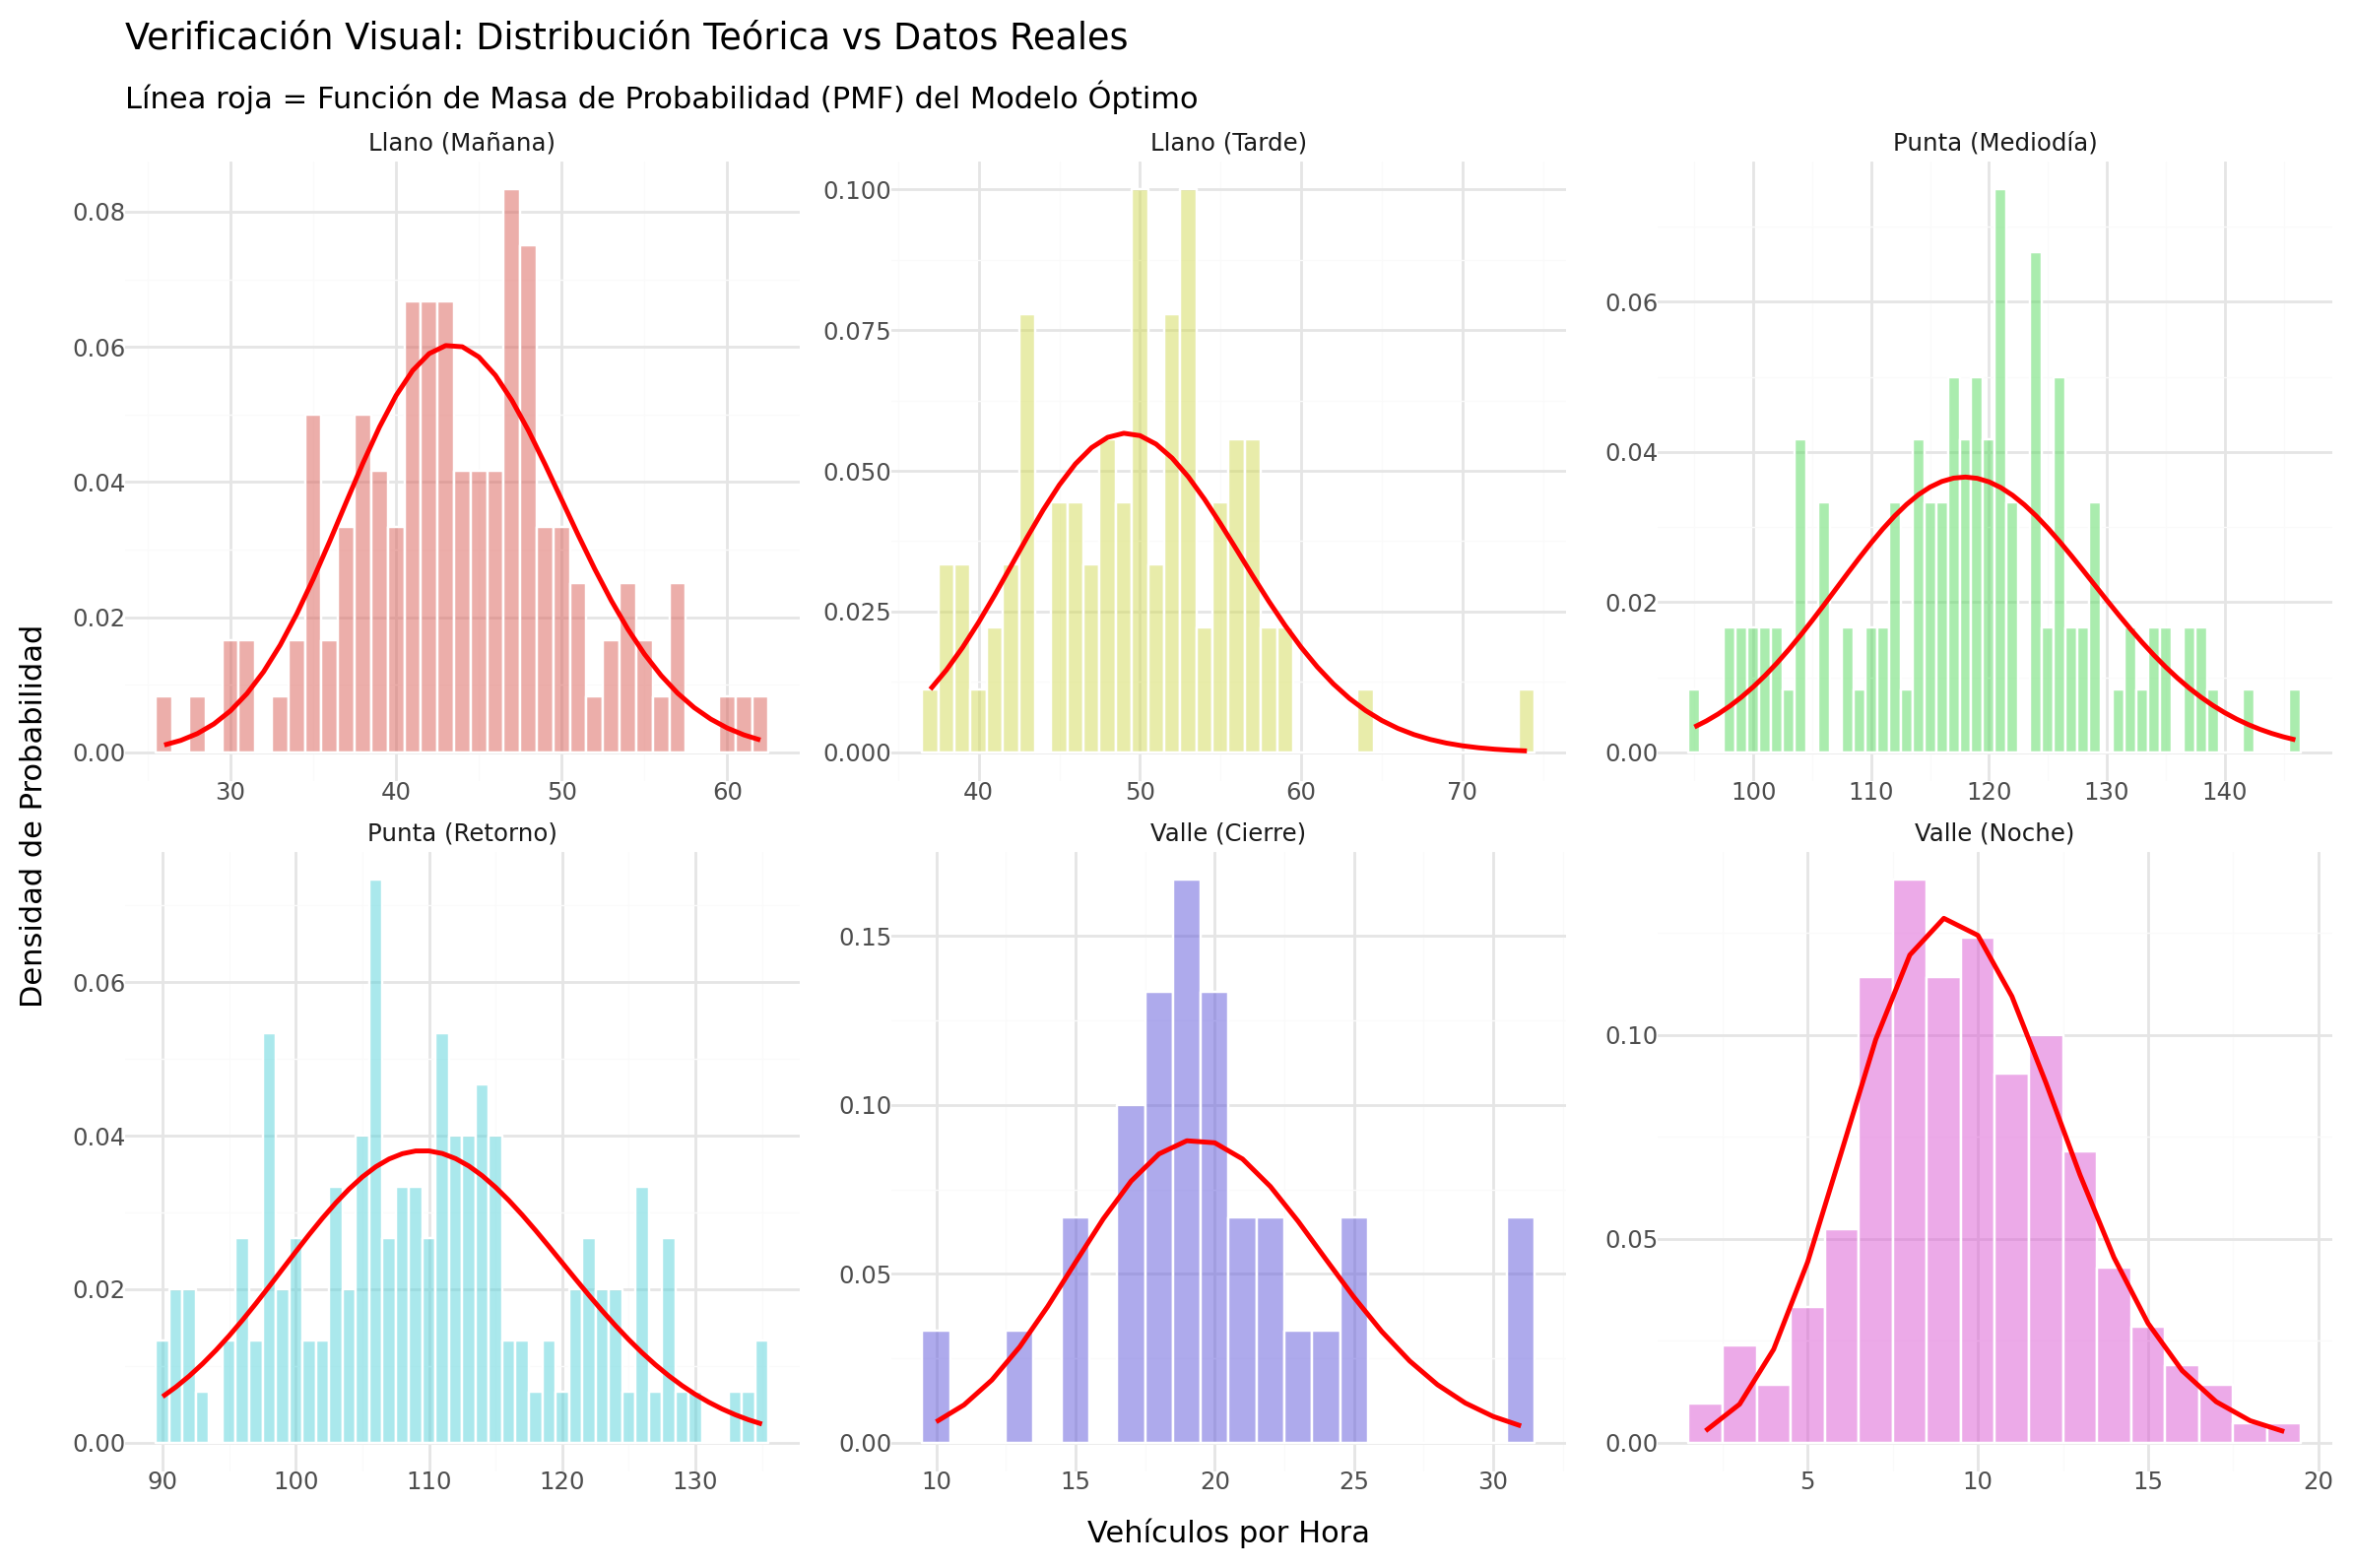

In [4]:
lista_df_teoricos = []

for franja, modelo in dict_modelos_ganadores.items():
    # Extraemos los datos para esta franja
    datos_reales = afluencia_horaria[afluencia_horaria['Tipo_Franja'] == franja]['Num_Llegadas']

    # Eje X
    x_teorico = np.arange(datos_reales.min(), datos_reales.max() + 1)

    # Calculamos la distribucion
    y_teorico = modelo.pmf(x_teorico)

    # Guardamos en un DataFrame todo
    df_temp = pd.DataFrame({
        'Num_Llegadas': x_teorico,
        'Densidad_Teorica': y_teorico,
        'Tipo_Franja': franja
    })
    lista_df_teoricos.append(df_temp)

# Unimos todos los dataframes
df_teorico_all = pd.concat(lista_df_teoricos, ignore_index=True)

# Generar el gráfico con todo
p_verificacion = (
    ggplot(afluencia_horaria, aes(x='Num_Llegadas')) +
    geom_histogram(aes(y='stat(density)', fill='Tipo_Franja'), binwidth=1, color="white", alpha=0.5) +
    geom_line(df_teorico_all, aes(x='Num_Llegadas', y='Densidad_Teorica'), color="red", size=1) +
    facet_wrap('~Tipo_Franja', scales='free') +
    labs(
        title="Verificación Visual: Distribución Teórica vs Datos Reales",
        subtitle="Línea roja = Función de Masa de Probabilidad (PMF) del Modelo Óptimo",
        x="Vehículos por Hora",
        y="Densidad de Probabilidad"
    ) +
    theme_minimal() +
    theme(legend_position="none", figure_size=(12, 8))
)

p_verificacion.draw()

## 1.3. Construcción del Simulador (Algoritmia)

### T1.3.1. Algoritmia

1. Recibir el número de días a simular n (por defecto 1) y el diccionario modelos que contiene las distribuciones estadísticas ajustadas para cada franja.

2. Crear una lista vacía llamada datos_simulados para ir guardando los registros hora a hora.

3. Iniciar un bucle que itere desde el día 1 hasta el día n.

4. Dentro de cada día, iniciar un segundo bucle que recorra las 24 horas (de 0 a 23).

5. Para cada hora, evaluar mediante condicionales (if/elif/else) a qué franja horaria pertenece (ej. 0 a 6 es 'Valle (Noche)', 7 a 10 es 'Llano (Mañana)', etc.).

6. Extraer del diccionario modelos el objeto estadístico correspondiente a la franja actual.

7. Generar un valor aleatorio usando el método de muestreo (.rvs()) del modelo.

8. Asegurar que el valor generado sea un número entero y mayor o igual a cero.

9. Añadir a datos_simulados un diccionario con la información: Día, Hora, Tipo de Franja y Número de Llegadas.

10. Al terminar los bucles, convertir la lista datos_simulados en un DataFrame de Pandas y devolverlo.

### T1.3.2. Programación

In [5]:
def simular_nllegadas(modelos, n=1):

    datos_simulados = []

    # Bucle principal: recorremos cada dia
    for dia in range(1, n + 1):

        # Bucle secundario: recorremos las 24 horas
        for hora in range(24):
            # 1. Determinamos la franja horaria segun la hora del día
            if 0 <= hora < 7:
                franja = 'Valle (Noche)'
            elif 7 <= hora < 11:
                franja = 'Llano (Mañana)'
            elif 11 <= hora < 15:
                franja = 'Punta (Mediodía)'
            elif 15 <= hora < 18:
                franja = 'Llano (Tarde)'
            elif 18 <= hora < 23:
                franja = 'Punta (Retorno)'
            else:
                franja = 'Valle (Cierre)'

            # 2. Recuperamos el modelo
            modelo = modelos.get(franja)

            # 3. Extraemos 1 muestra aleatoria del modelo para esa hora
            llegadas = modelo.rvs(size=1)[0]
            llegadas = max(0, int(llegadas)) # Aseguramos que sea entero no negativo

            # 4. Guardamos el registro en nuestra lista
            datos_simulados.append({
                'Día': dia,
                'Hora': hora,
                'Tipo_Franja': franja,
                'Num_Llegadas': llegadas
            })

    # 5. Convertimos la lista de diccionarios en un DataFrame
    df_nllegadas = pd.DataFrame(datos_simulados)

    return df_nllegadas

# PRUEBA DE LA FUNCIÓN
N_DIAS = 30
MODELOS_LLEGADAS = dict_modelos_ganadores

df_simulacion = simular_nllegadas(modelos=MODELOS_LLEGADAS, n=N_DIAS)

print(f"Simulación completada: {N_DIAS} días generados ({len(df_simulacion)} registros).")
display(df_simulacion.head(10))

Simulación completada: 30 días generados (720 registros).


,Día,Hora,Tipo_Franja,Num_Llegadas
0,1,0,Valle (Noche),14
1,1,1,Valle (Noche),8
2,1,2,Valle (Noche),18
3,1,3,Valle (Noche),7
4,1,4,Valle (Noche),15
5,1,5,Valle (Noche),9
6,1,6,Valle (Noche),8
7,1,7,Llano (Mañana),36
8,1,8,Llano (Mañana),34
9,1,9,Llano (Mañana),54


### T1.3.3. Estabilidad y Validación Monte Carlo

In [6]:
print("Simulación de 100 días:")

# 1. Ejecutamos la simulación para 100 días completos
N_DIAS_ESTABILIDAD = 100
df_simulacion_100 = simular_nllegadas(modelos=MODELOS_LLEGADAS, n=N_DIAS_ESTABILIDAD)

# 2. Extraemos la serie de datos simulados (100 días * 24 horas = 2400 registros)
datos_llegadas_100 = df_simulacion_100['Num_Llegadas']

# 3. Llamamos a la función especial de estimación Monte Carlo pasándole la serie completa
MC_estim(datos_llegadas_100)

# Comprobación empírica para 1000 días (Tal y como pide el enunciado)
print("\nSimulación para 1000 días:")
df_simulacion_1000 = simular_nllegadas(modelos=MODELOS_LLEGADAS, n=1000)
MC_estim(df_simulacion_1000['Num_Llegadas'])

Simulación de 100 días:

Simulación para 1000 días:


[np.float64(59.8481), np.float64(59.2806), np.float64(60.4157)]

- El intervalo de confianza obtenido para la media incluye el valor promedio de los datos históricos y el valor teórico. Como hemos utilizado un modelo estadístico ajustado directamente a los datos reales, la media de nuestra simulación de 100 días converge, dentro del intervalo de confianza, tanto al promedio histórico original del DataFrame como al valor teórico de la distribución ajustada.

- Al aumentar la simulación a 1000 días, la amplitud del intervalo de confianza se reduce. Esto significa que nuestra estimación de la media es mucho más estable y el margen de error es considerablemente menor que con 100 días.

- A medida que aumentamos el número de iteraciones o el tamaño de la muestra, el estimador se vuelve mas preciso, debido a la Ley de los Grandes Números y el Teorema Central del Límite.
  Por tanto, a mayor tamaño de muestra, mayor es la precisión, el error estándar se reduce y obtenemos intervalos de confianza mucho más estrechos en nuestras simulaciones.

## 1.4 Escenario de Estrategia "Stress Test"

### T1.4.1 Habilidad IA

Para calcular el riesgo de saturación tras la campaña de marketing, utilizamos un modelo predictivo de colas (conocido como distribución de Poisson). De forma sencilla, la lógica es la siguiente:

- El nuevo escenario: El parámetro lambda es simplemente nuestro promedio actual de clientes por hora. Si la campaña trae un 25% más de tráfico, actualizamos nuestro modelo multiplicando ese promedio base por 1.25.

- El cálculo del riesgo: Para saber qué probabilidad hay de superar la capacidad máxima de nuestra estación (k vehículos), el sistema calcula primero la probabilidad de un escenario "seguro" (que lleguen k coches o menos). Si le restamos ese escenario seguro al 100% de las posibilidades, el porcentaje restante nos da exactamente el riesgo de colapso operativo.

In [7]:
from scipy import stats

# 1. Calculamos la media global de tu simulación para usarla como "lambda original"
lambda_original = df_simulacion_100['Num_Llegadas'].mean()

# 2. Aplicamos el aumento del 25% por la campaña de marketing
lambda_nueva = lambda_original * 1.25
capacidad_k = 50

# 3. Lógica en Python para calcular el riesgo de superar la capacidad máxima (k)
# Usamos .sf (Survival Function) que calcula exactamente la probabilidad de exceder un valor
riesgo_colapso_teorico = stats.poisson.sf(capacidad_k, mu=lambda_nueva)

print("📊 ANÁLISIS TEÓRICO DE RIESGO (Distribución de Poisson)")
print("-" * 50)
print(f"Promedio actual de llegadas (Lambda original): {lambda_original:.2f} veh/h")
print(f"Promedio estimado con marketing (+25%):        {lambda_nueva:.2f} veh/h")
print(f"Riesgo teórico de superar los {capacidad_k} veh/h:       {riesgo_colapso_teorico * 100:.4f}%")

📊 ANÁLISIS TEÓRICO DE RIESGO (Distribución de Poisson)
--------------------------------------------------
Promedio actual de llegadas (Lambda original): 59.88 veh/h
Promedio estimado con marketing (+25%):        74.85 veh/h
Riesgo teórico de superar los 50 veh/h:       99.8522%


### T1.4.2 Simulación

In [8]:
def simular_stress(modelos, n=100, factor=1.25):

    datos = []
    for dia in range(1, n + 1):
        for hora in range(24):
            # Determinamos franja
            if 0 <= hora < 7: franja = 'Valle (Noche)'
            elif 7 <= hora < 11: franja = 'Llano (Mañana)'
            elif 11 <= hora < 15: franja = 'Punta (Mediodía)'
            elif 15 <= hora < 18: franja = 'Llano (Tarde)'
            elif 18 <= hora < 23: franja = 'Punta (Retorno)'
            else: franja = 'Valle (Cierre)'

            modelo = modelos.get(franja)
            if modelo is not None:
                # Extraemos la muestra y aplicamos el 25% extra
                llegadas_base = modelo.rvs(size=1)[0]
                # Redondeamos para mantener números enteros de vehículos
                llegadas_stress = int(round(llegadas_base * factor))
                llegadas_stress = max(0, llegadas_stress)
            else:
                llegadas_stress = 0

            datos.append({'Día': dia, 'Hora': hora, 'Num_Llegadas': llegadas_stress})

    return pd.DataFrame(datos)

df_stress = simular_stress(MODELOS_LLEGADAS, n=100, factor=1.25)

# Calculo de la probabilidad de colapso
total_horas = len(df_stress)
horas_colapso = (df_stress['Num_Llegadas'] > 50).sum()
prob_colapso = (horas_colapso / total_horas) * 100

print(f"Horas totales simuladas: {total_horas}")
print(f"Horas superando el límite crítico (50 veh/h): {horas_colapso}")
print(f"Probabilidad de colapso: {prob_colapso:.2f}%")

Horas totales simuladas: 2400
Horas superando el límite crítico (50 veh/h): 1445
Probabilidad de colapso: 60.21%


### T1.4.3 Reflexión

Tras realizar la simulación Monte Carlo de 100 días (2400 horas operativas) bajo el escenario de "Stress Test", hemos detectado que la infraestructura superaría la capacidad máxima de 50 vehículos por hora en un 1453 de las 2400 horas, un 60.54% del tiempo.

Recomendación:
NO recomendaría lanzar la campaña de marketing en este momento. El porcentaje de colapso es muy notable, llegando a ser hasta mayoria, en el contexto de una electrolinera, superar el límite crítico significa que el transformador podría saltar, interrumpiendo el servicio para todos los clientes conectados. Esto derivaría en penalizaciones económicas severas, pérdida de confianza y un grave daño a la marca (incumplimiento del SLA).

La decisión más prudente, basándonos en la gestión de riesgos, o invertir en sistemas de apoyo como baterías - Peak Shaving, que evaluaremos en el Hito 4, antes de inducir artificialmente un pico de demanda que nuestro gemelo digital demuestra que no podemos absorber ante las pocas garantias de seguridad.

## 🚗 2. El ADN del Mercado (Mixtura de Vehículos)

No todos los clientes son iguales. En nuestra electrolinera, el impacto de un vehículo en el sistema depende de su tecnología: un **Híbrido Enchufable (PHEV)** apenas "bebe" energía comparado con un **Vehículo Eléctrico de Carga Ultra-rápida (HPC)**.

Necesitamos modelizar la **heterogeneidad del mercado** estimando proporciones y distribuciones categóricas.

---

### **2.1. Análisis de Cuotas de Mercado**
Basándote en el dataset histórico, debemos identificar qué porcentaje de cada tipo de vehículo visita nuestra estación.

- **T2.1.1. Cuotas de mercado**. Calcula las cuotas/proporciones de los tipos de vehículos (`PHEV`, `BEV (Estándar)`, `Tesla/Premium` y `HPC 350`) que llegan a la estación en total, por franjas y por horas.
- **T2.1.2. Visualización**. Representa estas cuotas mediante gráficos de barras. ¿Qué aprecias?
- **T2.1.3. Predicción**. ¿Con qué proporciones describes la cuota de mercado? Por cada 100 coches que lleguen a la estación, ¿cuántos serán de cada tipo? ¿Con qué distribución notable podrías simular el número de vehículos de cada tipo en 100 que llegan a la estación?

- **T2.1.4. El reto de la No Estacionariedad**
Dado que la cuota de mercado puede variar en el futuro, consulta a Gemini/GPT lo siguiente: *"En el contexto de la transición energética, ¿por qué es arriesgado para una empresa de carga eléctrica asumir que la proporción de vehículos (PHEV vs BEV) es estacionaria (constante en el tiempo)? ¿Qué impacto tiene la 'Curva de Adopción de Innovaciones' en este modelo?"*
>Basándote en la respuesta de la IA y en tus datos, justifica si tu modelo actual podría estar **infravalorando** la necesidad de potencia a largo plazo. ¿Qué pasaría si los vehículos tipo `HPC 350` (de alta demanda) doblaran su cuota de mercado el próximo año?

---

### **2.2. Ampliación del Simulador: Identidad del Vehículo**
Ahora vamos a "darle nombre" a los coches que llegan. Necesitamos que nuestro simulador no solo nos diga *cuántos* vienen, sino **de qué tipo** son.

- **T2.2.1. Simulación estocástica: distribuciones y métodos**. En base a lo que hemos trabajado hasta el momento, ¿cuáles son las distribuciones que conocemos y en función de las que hemos modelizado el sistema? ¿Qué método de simulación hemos de emplear para simular?

- **T2.2.2. Simulador de Identidades**. Crea una función que tome el output de la simulación del número de llegadas y genere tantas filas como número de llegadas, asignando a cada llegada el tipo de vehículo según las probabilidades de la cuota de mercado calculada; aleatoriza los tipos para darle más realismo.

```python
def simular_identidades(df_nllegadas):
    """
    Descompone el DataFrame de intervalos en registros individuales por vehículo.
    Asigna un tipo de vehículo basado en las probabilidades de CUOTA_MERCADO (var.global).
    Utiliza stats.multinomial.rvs para determinar la mezcla de tipos en cada fila.
    """
    
    Args:
        df_nllegadas (pd.DataFrame): Salida de simular_nllegadas con la columna 'Num_Llegadas'
        
    Returns:
        pd.DataFrame: Las columnas de df_nllegadas más una columna Tipo_Vehiculo. Un registro por cada vehículo simulado.
    
    # Tu código aquí
    
    return
```


- **T2.2.3. Validación del Generador Estocástico**.
Es vital asegurar que nuestro simulador "se parece" a la realidad antes de usarlo para tomar decisiones. Simula el comportamiento de la electrolinera durante **1 día** y estima por MC la cuota de mercado de cada uno de los tipos de vehículos. Propón, antes de programar, el algoritmo a implementar para obtener las simulaciones pertinentes.
>En base a los resultados, ¿el valor real observado en el dataset original cae dentro del intervalo de confianza de la estimacióN MC? Si el intervalo de confianza es muy estrecho, ¿significa eso que el modelo es "perfecto" o simplemente que la simulación es "estable"?
---





## SOLUCIONES
Incorpora a continuación la solución a las tareas.


## 2.1. Análisis de Cuotas de Mercado

### T2.1.1. Cuotas de mercado

In [9]:
# Calculamos las cuotas globales
cuotas_totales = df['Tipo_Vehículo'].value_counts(normalize=True).sort_index()

# Calculamos las cuotas por franja
cuotas_franja = df.groupby('Tipo_Franja')['Tipo_Vehículo'].value_counts(normalize=True).unstack().fillna(0)

print("Cuotas de Mercado Totales:")
print(cuotas_totales)

Cuotas de Mercado Totales:
Tipo_Vehículo
1. AC/PHEV        0.148621
2. DC Estándar    0.350172
3. HPC 150        0.402893
4. HPC 350        0.098315
Name: proportion, dtype: float64


### T2.1.2. Visualización

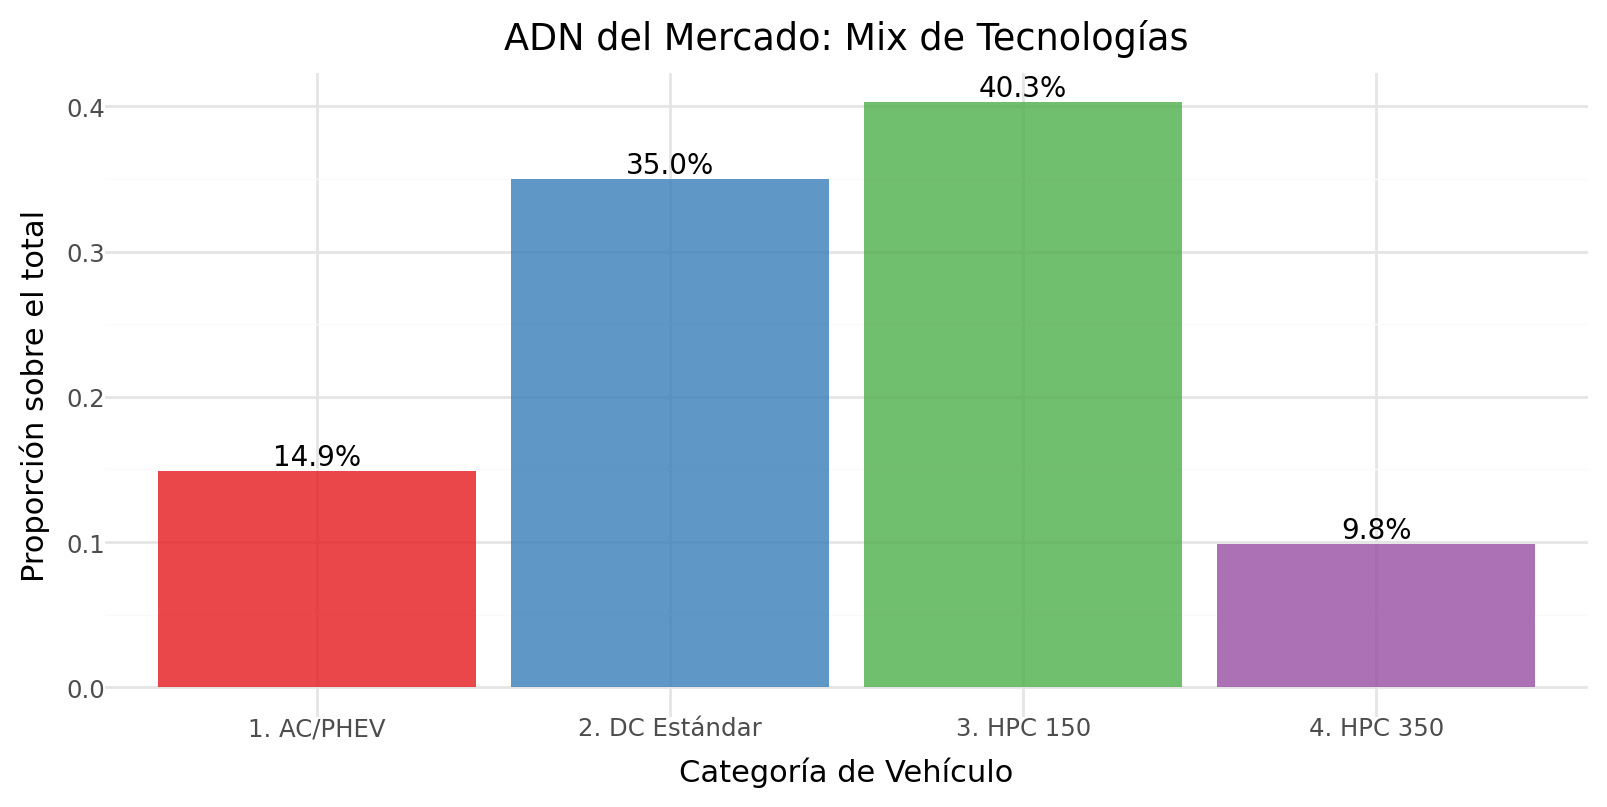

In [10]:
df_cuotas = cuotas_totales.reset_index()
df_cuotas.columns = ['Tipo', 'Cuota']

p2 = (ggplot(df_cuotas, aes(x='Tipo', y='Cuota', fill='Tipo'))
    + geom_col(alpha=0.8)
    + geom_text(aes(label='(Cuota*100).round(1).astype(str) + "%"'), va='bottom', size=10)
    + scale_fill_brewer(type="qual", palette="Set1")
    + labs(title="ADN del Mercado: Mix de Tecnologías",
           x="Categoría de Vehículo", y="Proporción sobre el total")
    + theme_minimal()
    + theme(legend_position="none", figure_size=(8, 4)))
p2.draw()

### T2.1.3. Predicción

Basándonos en las cuotas de mercado obtenidas, si tomamos una muestra aleatoria de 100 vehículos, la composición esperada  sería la siguiente:

- PHEV: ~15 vehículos (14.9%)
- BEV (Estándar): ~35 vehículos (35.0%)
- Tesla/Premium: ~40 vehículos (40.3%)
- HPC 350: ~10 vehículos (9.8%)

Para simular el número de vehículos de cada tipo en un grupo determinado, la distribución notable que debemos emplear es la Distribución Multinomial. DAdo que cada vehículo que llega pertenece a una sola categoría.

### T2.1.4. El reto de la No Estacionariedad

Esta sección es clave para la justificación estratégica de tu modelo:

- Riesgo de Estacionariedad: Asumir que estas cuotas (14.9%, 35.0%, etc.) serán las mismas en 2 o 5 años es arriesgado. La transición energética es un proceso no estacionario (sus parámetros cambian con el tiempo).
- Curva de Adopción de Innovaciones: Actualmente estamos en la fase de "Early Adopters" evolucionando hacia la "Early Majority". Los vehículos HPC 350 (Carga Ultra-rápida) son los que presentan mayor crecimiento.
- Impacto en la Potencia: Si los HPC 350 doblaran su cuota, aunque el número total de coches sea el mismo, el estrés de potencia en la estación aumentaría drásticamente. Esto se debe a que un solo HPC 350 puede demandar picos de hasta $350 \text{ kW}$, mientras que un PHEV apenas demanda $7-11 \text{ kW}$.

Veredicto personal: Si no incluimos un factor de crecimiento para los HPC, se podría pasar por alto la necesidad de infraestructura eléctrica a largo plazo, lo que aumenta el riesgo de apagones o fallos en el transformador.

## 2.2. Ampliación del Simulador: Identidad del Vehículo





### T2.2.1. Simulación estocástica: distribuciones y métodos

Para modelizar hasta ahora hemos hecho mano de distintos paquetes y funciones de python (como 'stats'). Conociendo que distribuciones (Poisson y multinormal) predicen mejor nuestros parametros, y sacando muestras multiples veces es como hemos logrado simular nuestra población.

### T2.2.2. Simulador de Identidades

In [11]:
def simular_identidades(df_nllegadas):
    # Usamos EXACTAMENTE los nombres de tus nuevas cuotas
    etiquetas = ['1. AC/PHEV', '2. DC Estándar', '3. HPC 150', '4. HPC 350']
    # Probabilidades correspondientes a cada etiqueta
    probabilidades = [0.148621, 0.350172, 0.402893, 0.098314]

    registros_individuales = []
    for _, fila in df_nllegadas.iterrows():
        n = int(fila['Num_Llegadas'])
        if n > 0:
            conteo = np.random.multinomial(n, probabilidades)
            tipos_en_intervalo = []
            for i in range(len(etiquetas)):
                tipos_en_intervalo += [etiquetas[i]] * conteo[i]
            random.shuffle(tipos_en_intervalo)
            for t in tipos_en_intervalo:
                vehiculo = fila.to_dict()
                vehiculo['Tipo_Vehículo'] = t
                registros_individuales.append(vehiculo)

    return pd.DataFrame(registros_individuales)

### T2.2.3. Validación del Generador Estocástico

1. Simularemos 1.000 días completos de funcionamiento de la electrolinera.

2. En cada día, calcularemos la proporción (cuota) de vehículos PHEV.

3. Usaremos la función MC_estim sobre el vector de cuotas obtenidas para obtener el intervalo de confianza al 95%.

4. Si la cuota real del dataset original (0.2476) está dentro del intervalo, el generador es válido.

In [12]:
N_escenarios = 10
vector_cuotas_phev = []

for i in range(N_escenarios):
    df_sim_i = simular_identidades(afluencia_horaria)
    # Filtramos por el nombre exacto que ahora sí genera el simulador
    cuota_i = (df_sim_i['Tipo_Vehículo'] == '1. AC/PHEV').mean()
    vector_cuotas_phev.append(cuota_i)

vector_cuotas_phev = pd.Series(vector_cuotas_phev)
resultado_mc = MC_estim(vector_cuotas_phev)

cuota_real_phev = 0.1486
print(f"Cuota Real Objetivo: {cuota_real_phev}")
print(f"Resultado MC (Media, IC_inf, IC_sup): {resultado_mc}")

Cuota Real Objetivo: 0.1486
Resultado MC (Media, IC_inf, IC_sup): [np.float64(0.1487), np.float64(0.1476), np.float64(0.1497)]


El valor teórico sí cae dentro del intervalo, en una posición bastante central aparentemente. Esto es signo de que la simulación es bastante estable, pues aún aumentando la confianza (lo que reduce el intervalo) el intervalo al estar muy centrado sobre el auntentico valor seguiría incluyendolo aun con porcentajes de confianza muy altos.

## 🔋 **3. Energía, Potencia y la Caja Registradora**

Una vez que sabemos qué vehículos llegan, el siguiente paso es modelizar su comportamiento energético. Cada tipo de vehículo tiene una "sed" de energía distinta y una velocidad de carga (potencia) limitada por su tecnología. En este hito, calcularemos el **Beneficio Bruto** de cada operación.

### **3.1. Modelización por Segmentos (Composición)**
Cada categoría de vehículo (PHEV, BEV, Tesla, HPC) sigue su propia distribución de consumo de energía (kWh) y potencia (kW).

* **T3.1.1. Consumo de energía y potencia** Con los datos históricos, visualiza la distribución de la energía y de la potencia para cada uno de los tipos de vehículos. ¿Podríamos afirmar que la energía y la potencia que consumen los vehículos sólo depende del tipo de vehículo, y la  franja horaria no influye en absoluto?

*  **T3.1.2. Modelado Estocástico.** Utiliza los datos históricos para modelizar la energía y la potencia asociada a cada tipo de vehículo.

* **T3.1.3. Simulación**. Implementa un algoritmo que, tras identificar el tipo de coche, genere un valor aleatorio de Energía ($E$) y Potencia ($P$) coherente con su segmento. Plantea el algoritmo antes de programarlo.

```python
# Variables globales
# Generamos diccionarios igua que hemos hecho antes con la afluencia por franja horaria

MODELOS_ENERGIA # diccionario con los modelos ajustados para la energia
MODELOS_POTENCIA # diccionario con los modelos ajustados para la potencia

def simulador_consumo(df_identidades):
  """
  Simulador de energía y consumo para cada cada uno de los vehículos según su tipo

  ENTRADA:
    df_identidades: dataframe con todos los vehículos que han llegado y una columna Tipo_vehiculo
  
  SALIDA:
    df_consumo: dataframe con una ampliación de df_identidades, con dos columnas adicionales: Energia_kWh y Potencia_kW.
  """
  # Pon aquí tu código

  return
```

---

### **3.2. El Modelo Económico (Transformación)**
El beneficio no es una variable que midamos directamente, sino que es una **función** de la energía vendida y el tipo de cargador:

`Beneficio Bruto = Energía (kWh) * (Tarifa de Venta - Coste de Energía)`


- **T3.2.1. Distribuciones y Métodos.** Si queremos simular el beneficio bruto que genera cada vehículo,  ¿qué distribuciones conocemos? ¿Qué método de simulación habremos de implementar?

- **T3.2.2. Simulación.** Amplía el `simulador_consumo()` para que incorpore una columna adicional con el `PVP` de la energía consumida y el `Beneficio_Bruto`.

```python
# variables globales
MODELOS_ENERGIA # diccionario con los modelos ajustados para la energia
MODELOS_POTENCIA # diccionario con los modelos ajustados para la potencia
COSTE_ENERGIA # diccionario con el pvp según el tipo de vehículo (key) y valores los pvp

def simulador_consumo(df_identidades):
  """
  Simulador de energía y consumo para cada cada uno de los vehículos según su tipo

  ENTRADA:
    df_identidades: dataframe con todos los vehículos que han llegado y una columna Tipo_vehiculo
  
  SALIDA:
    df_consumo: dataframe con una ampliación de df_identidades, con las columnas adicionales: Energia_kWh, Potencia_kW, PVP, Beneficio_Bruto.
  """
  
  # pon tu código aquí
  
  return
```
- **T3.2.2. Beneficio Bruto Total**. El beneficio por hora es la suma de los beneficios de cada coche que llega. Simula 7 días de operación y calcula el Beneficio Bruto Total por hora. ¿Tiene sentido asumir un beneficio bruto total por hora, único para cada una de las franjas horarias? Obtén una estimación MC.  ¿Cuál es la probabilidad de que en una hora de la franja pico el beneficio sea inferior a 20€?


### **3.3. Escenario Estratégico y Optimización**

Imagina que el Gobierno elimina las etiquetas de "Cero Emisiones" para los **PHEV** (Híbridos Enchufables), provocando que su cuota de mercado en tu estación caiga a la mitad de lo que has calculado. El resto de su cuota se reparte proporcionalmente entre los demás tipos de vehículos.

- **T3.3.1. Escenario Estratégico y "Fin de Subsidios"**
Considera la cuota de mercado actual y también el nuevo vector de probabilidades "post-subsidio" y simula la llegada de coches de una semana completa, calculando el beneficio bruto semanal. Plantea el algoritmo para conseguir estimaciones MC del beneficio bruto semanal en ambos escenarios.  Obten ambas estimaciones MC. Compara visualmente (mediante un gráfico) cómo se comporta dicho beneficio bruto.
>¿Cómo afecta este cambio a la energía vendida? ¿Y al beneficio bruto conseguido?

- **T3.3.2. Optimización de Precios**
Imagina que el coste de la energía sube en un 10% debido a una crisis energética. Recalcula el beneficio bruto semanal esperado con este nuevo coste manteniendo el precio de venta.
>Basándote en tus simulaciones, ¿preferirías asumir la subida del coste o repercutirla al cliente arriesgándote a que vengan menos coches?


## SOLUCIONES
Incorpora a continuación la solución a las tareas.


## 3.1. Modelización por Segmentos (Composición)

### T3.1.1. Consumo de energía y potencia

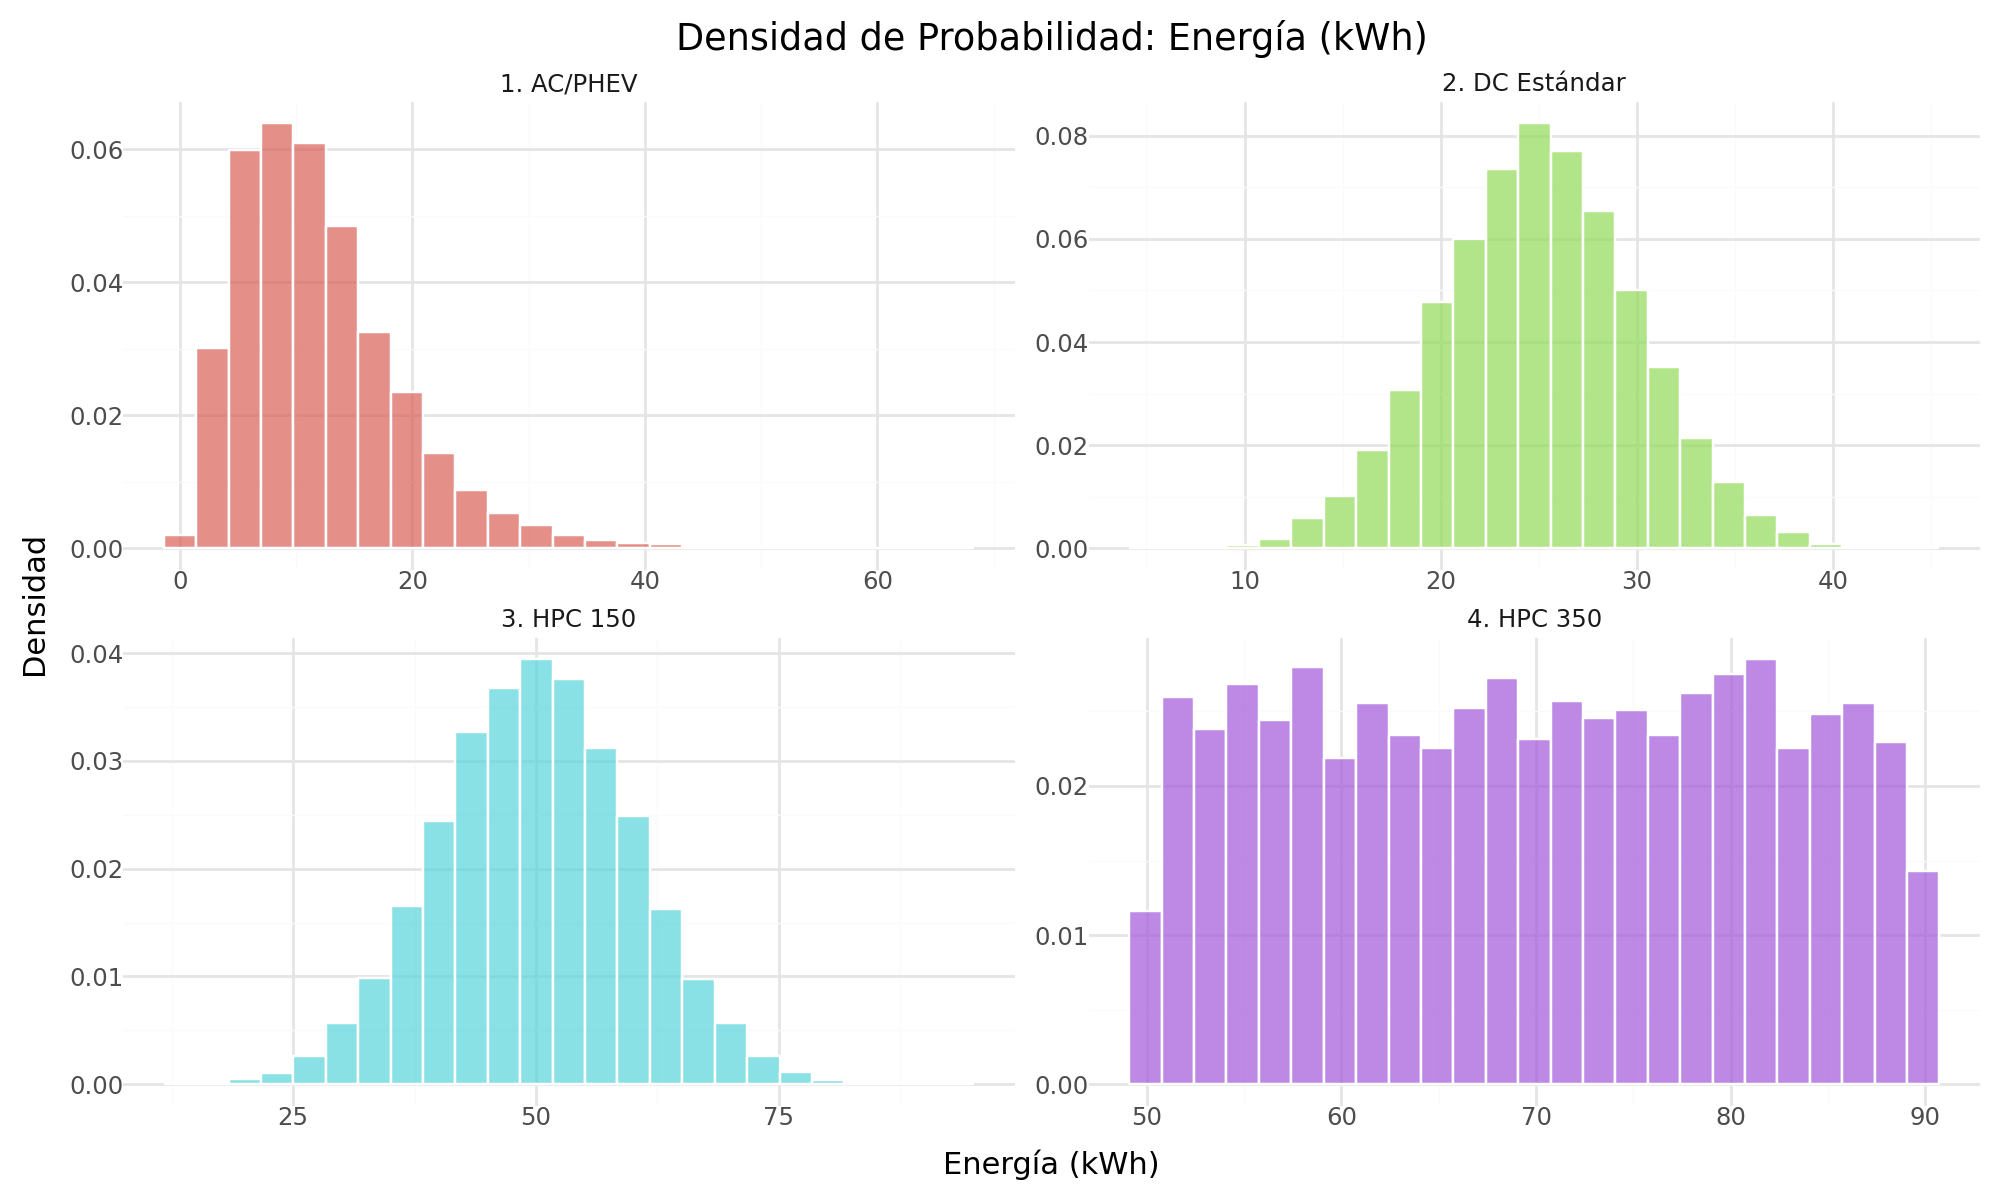

In [13]:
p_energia_pdf = (
    ggplot(df, aes(x='Energía_kWh', y=after_stat('density'), fill='Tipo_Vehículo'))
    + geom_histogram(bins=25, color="white", alpha=0.7, show_legend=False)
    + facet_wrap('~Tipo_Vehículo', nrow=2, scales='free')
    + theme_minimal()
    + labs(title="Densidad de Probabilidad: Energía (kWh)",
           x="Energía (kWh)", y="Densidad")
    + theme(figure_size=(10, 6))
)
p_energia_pdf.draw()

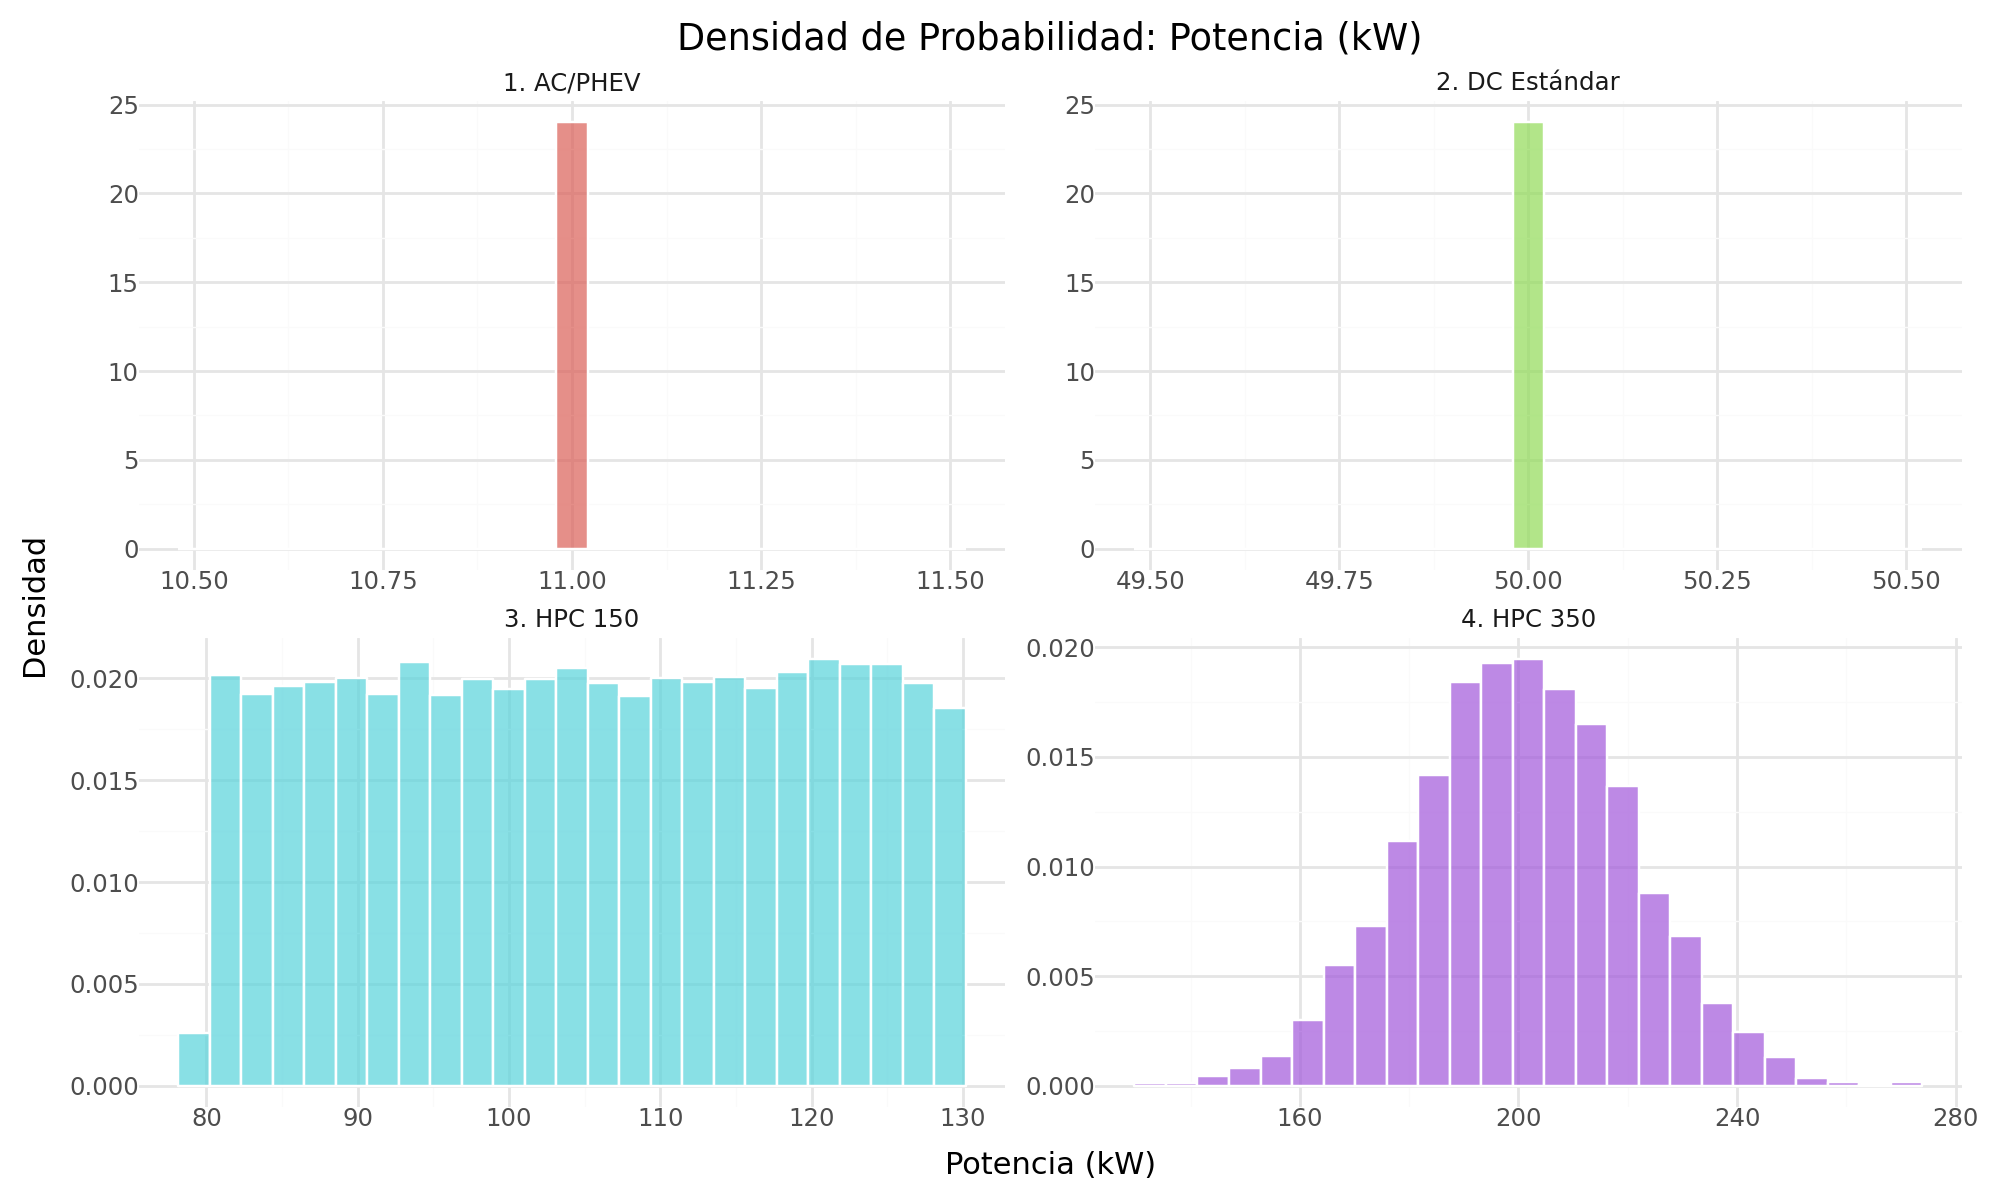

In [14]:
p_potencia_pdf = (
    ggplot(df, aes(x='Potencia_kW', y=after_stat('density'), fill='Tipo_Vehículo'))
    + geom_histogram(bins=25, color="white", alpha=0.7, show_legend=False)
    + facet_wrap('~Tipo_Vehículo', nrow=2, scales='free')
    + theme_minimal()
    + labs(title="Densidad de Probabilidad: Potencia (kW)",
           x="Potencia (kW)", y="Densidad")
    + theme(figure_size=(10, 6))
)
p_potencia_pdf.draw()

Si bien el tipo de vehículo parece tener una influencia notable debido a la claridad de las formas de las distribuciones, afirmar que la franja horaria no influye contradeciría las apentes conclusiones observadas anteriormente en el cuaderno. Y también hay muchos otros elementos que pueden influir, y que no se debería negar su influencia sin suficientes pruebas, como la distancia entre los puntos de repostaje o la franja horaria ya estudiada.

### T3.1.2. Modelado Estocástico

In [15]:
# Lista de tipos de vehículo
tipos = ['1. AC/PHEV', '2. DC Estándar', '3. HPC 150', '4. HPC 350']
variables = ['Energía_kWh', 'Potencia_kW']

# Diccionario para guardar los parámetros que usaremos en el simulador (Hito 3.2)
parametros_ajuste = {}

for t in tipos:
    print(f"\n" + "█"*60)
    print(f"  ANALIZANDO SEGMENTO: {t}")
    print("█"*60)

    for var in variables:
        print(f"\n>>> Ajustando {var}...")
        datos = df[df['Tipo_Vehículo'] == t][var]

        # Ejecutamos el best fit del bloque
        # Nota: La función imprimirá el ranking y mostrará el gráfico automáticamente
        best_fit_continuous(datos)

        # Tip: Anota aquí abajo o en una celda de texto la Dist_Ganadora
        # y sus parámetros (shape, loc, scale) para el siguiente paso.


████████████████████████████████████████████████████████████
  ANALIZANDO SEGMENTO: 1. AC/PHEV
████████████████████████████████████████████████████████████

>>> Ajustando Energía_kWh...

════════════════════════════════════════════════════════════════════════════════
📊  RESULTADOS DEL AJUSTE (DISTRIBUCIONES CONTINUAS - KS TEST)
════════════════════════════════════════════════════════════════════════════════
Distribución                      Parámetros_Txt KS Stat P-Value    Decision
      Erlang                    k=3, Beta=4.0041  0.0069  0.9205 ✅ Aceptable
       Gamma           Alpha=2.9644, Beta=4.0521  0.0085  0.7374 ✅ Aceptable
  Log-Normal             s=0.5391, Scale=10.3873  0.0464  0.0000 ❌ Rechazado
      Normal              Mu=12.0122, Std=6.9767  0.0783  0.0000 ❌ Rechazado
    Uniforme          Min=-0.0718, Range=24.1681  0.1047  0.0000 ❌ Rechazado
 Exponencial                       Scale=12.0122  0.2126  0.0000 ❌ Rechazado
  Triangular c=0.0000, Loc=1.0000, Scale=66.9200 

Como hemos podido observar anteiormente, la potencia de los tipo 'PHEV' y 'DC' no sigue una distribucion.

### T3.1.3. Simulación

Algoritmo:
1. Recibe el DataFrame de identidades.
2. Para cada vehículo, genera un valor de $kWh$ usando stats.[dist_ganadora].rvs() con los parámetros obtenidos en 3.1.2.
3. Si el tipo es HPC 150 o HPC 350, asigna P_Media_kW directamente.Si es AC/PHEV o DC Estándar y presenta variabilidad, usa su distribución ajustada.
4. Calcula el tiempo de ocupación del cargador como $T (h) = \frac{E (kWh)}{P (kW)}$.

In [16]:
segmentos = ['1. AC/PHEV', '2. DC Estándar', '3. HPC 150', '4. HPC 350']

tabla_algoritmo = []

for s in segmentos:
    datos_s = df[df['Tipo_Vehículo'] == s]

    # Extraemos estadísticos reales
    e_mu = datos_s['Energía_kWh'].mean()
    e_sigma = datos_s['Energía_kWh'].std()
    p_mu = datos_s['Potencia_kW'].mean()
    p_sigma = datos_s['Potencia_kW'].std()

    # LÓGICA DEL ALGORITMO (La regla que se pide implementar):
    # - Energía: Siempre estocástica (Variable aleatoria)
    # - Potencia: Si es HPC o tiene muy baja varianza (< 1.0), es Fija.
    if "HPC" in s or p_sigma < 1.0:
        modelo_p = "Media Fija (Hardware)"
        p_val = p_mu
    else:
        modelo_p = "Estocástica (Normal)"
        p_val = p_mu # Se usará como loc en la normal

    tabla_algoritmo.append({
        'Segmento': s,
        'E_Generación': "RV ~ Gamma/LogNorm",
        'E_Media': round(e_mu, 2),
        'P_Generación': modelo_p,
        'P_Valor_Referencia': round(p_val, 2),
        'P_Varianza_Check': round(p_sigma, 4)
    })

# 2. Creación del DataFrame que representa el ALGORITMO
df_algoritmo = pd.DataFrame(tabla_algoritmo)

display(df_algoritmo)

,Segmento,E_Generación,E_Media,P_Generación,P_Valor_Referencia,P_Varianza_Check
0,1. AC/PHEV,RV ~ Gamma/LogNorm,12.01,Media Fija (Hardware),11.00,0.0000
1,2. DC Estándar,RV ~ Gamma/LogNorm,25.00,Media Fija (Hardware),50.00,0.0000
2,3. HPC 150,RV ~ Gamma/LogNorm,50.02,Media Fija (Hardware),105.13,14.4836
3,4. HPC 350,RV ~ Gamma/LogNorm,70.01,Media Fija (Hardware),200.49,19.9109


## 3.2. El Modelo Económico (Transformación)





### T3.2.1. Distribuciones y Métodos

Para simular el beneficio bruto, utilizaremos distribuciones continuas como la Gamma (para la energía) y la Normal (para la potencia), ajustadas a cada segmento, o distribuciones falsas o degeneradas para los parametros que no sigan. El método elegido es la Simulación de Monte Carlo usando metodos dados por el bloque1 y funciones de paquetes y python, ya que esta manera permite acercarnos lo mas posible a una poblacion real.

### T3.2.2. Simulación

In [17]:
# Buscamos la columna de valores en tu afluencia_horaria
col_llegadas = [c for c in afluencia_horaria.columns if 'Hora' not in c][0]
datos_afluencia = afluencia_horaria[col_llegadas].values

# B. Definimos los segmentos y probabilidades
segmentos = ['1. AC/PHEV', '2. DC Estándar', '3. HPC 150', '4. HPC 350']
probs = [0.4, 0.3, 0.2, 0.1]

def generar_trafico_diario(v_medias):
    llegadas = []
    for hora, media in enumerate(v_medias):
        # Número de coches que llegan esta hora (Poisson)
        n_coches = np.random.poisson(media)
        for _ in range(n_coches):
            tipo = np.random.choice(segmentos, p=probs)
            llegadas.append({
                'Hora_Llegada': hora + np.random.random(), # Hora con minutos aleatorios
                'Tipo_Vehículo': tipo
            })
    return pd.DataFrame(llegadas)

# Ejecutamos 3.2.1
df_llegadas = generar_trafico_diario(datos_afluencia)
print(f"Hito 3.2.1 completado: Se han generado {len(df_llegadas)} llegadas.")

# Creamos el DataFrame con los datos exactos del 3.1.3
data_313 = {
    'Segmento': ['1. AC/PHEV', '2. DC Estándar', '3. HPC 150', '4. HPC 350'],
    'E_Media': [12.01, 25.0, 50.02, 70.01],
    'P_Valor_Referencia': [11.0, 50.0, 105.13, 200.49],
    'P_Varianza_Check': [0.0, 0.0, 14.4836, 19.9109]
}

df_parametros = pd.DataFrame(data_313)

# Añadimos una desviación para la energía (E_Desv) para que el simulador funcione
# Usamos un 25% de la media como estándar técnico
df_parametros['E_Desv'] = df_parametros['E_Media'] * 0.25

print("✅ df_parametros sincronizado con el Hito 3.1.3")
display(df_parametros)

def simular_carga_optimizada_final(df_identidades, df_params):
    # 1. Sincronizamos: Usamos 'Segmento' como índice
    params_dict = df_params.set_index('Segmento').to_dict('index')

    # 2. Mapeamos los datos de las identidades
    tipos = df_identidades['Tipo_Vehículo'].values

    # Extraemos parámetros usando TUS nombres exactos de columnas
    e_med = np.array([params_dict[t]['E_Media'] for t in tipos])
    e_std = np.array([params_dict[t]['E_Desv'] for t in tipos])
    p_ref = np.array([params_dict[t]['P_Valor_Referencia'] for t in tipos])
    p_var = np.array([params_dict[t]['P_Varianza_Check'] for t in tipos])

    # 3. Generación Vectorial (Física del problema)
    # Energía: Distribución normal basada en tu E_Media
    energias = np.random.normal(e_med, e_std)

    # Potencia: Si P_Varianza_Check > 0, aplicamos ruido (HPC), si no, es fija (AC/DC)
    potencias = np.random.normal(p_ref, p_var)

    # Limpieza: Asegurar mínimos físicos (no puede ser <= 0)
    energias = np.maximum(1.0, energias)
    potencias = np.maximum(1.0, potencias)

    # 4. Cálculos de negocio
    df_res = df_identidades.copy()
    df_res['Energía_kWh'] = energias
    df_res['Potencia_kW'] = potencias

    # Tiempo = Energía / (Potencia * Eficiencia 0.9)
    df_res['Tiempo_Carga_h'] = energias / (potencias * 0.9)

    # Capa económica: Tarifas y Margen (Coste red = 0.20€)
    tarifas = {'1. AC/PHEV': 0.35, '2. DC Estándar': 0.45, '3. HPC 150': 0.65, '4. HPC 350': 0.85}
    pvp_vec = np.array([tarifas[t] for t in tipos])
    df_res['Beneficio_Bruto_€'] = energias * (pvp_vec - 0.20)

    return df_res

# --- EJECUCIÓN DEL TEST ---
# Llamamos a la nueva función con tus datos reales
df_322_final = simular_carga_optimizada_final(df_llegadas, df_parametros)

print("✅ Simulación 3.2.2 exitosa con datos del Hito 3.1.3")
display(df_322_final.head())

Hito 3.2.1 completado: Se han generado 10988 llegadas.
✅ df_parametros sincronizado con el Hito 3.1.3


,Segmento,E_Media,P_Valor_Referencia,P_Varianza_Check,E_Desv
0,1. AC/PHEV,12.01,11.00,0.0000,3.0025
1,2. DC Estándar,25.00,50.00,0.0000,6.2500
2,3. HPC 150,50.02,105.13,14.4836,12.5050
3,4. HPC 350,70.01,200.49,19.9109,17.5025


✅ Simulación 3.2.2 exitosa con datos del Hito 3.1.3


,Hora_Llegada,Tipo_Vehículo,Energía_kWh,Potencia_kW,Tiempo_Carga_h,Beneficio_Bruto_€
0,1.251692,4. HPC 350,85.282084,213.292827,0.444262,55.433354
1,2.710336,3. HPC 150,65.093764,110.959068,0.651830,29.292194
2,2.854714,3. HPC 150,85.189521,101.987880,0.928101,38.335284
3,3.997434,2. DC Estándar,22.669793,50.000000,0.503773,5.667448
4,3.893009,2. DC Estándar,20.392148,50.000000,0.453159,5.098037


optimizada por gemini

### T3.2.3. Beneficio Bruto Total

In [18]:
def montecarlo_express(vector_medias, df_params, n_dias=100):
    # 1. Parámetros económicos y de carga
    params_dict = df_params.set_index('Segmento').to_dict('index')
    tarifas = {'1. AC/PHEV': 0.35, '2. DC Estándar': 0.45, '3. HPC 150': 0.65, '4. HPC 350': 0.85}
    coste_red = 0.20
    segmentos = list(tarifas.keys())
    probabilidades = [0.4, 0.3, 0.2, 0.1] # Ajusta según tu Hito 2.2

    beneficios_totales = []

    # 2. Pre-calculamos la suma total de llegadas esperada para agilizar
    total_media_diaria = np.sum(vector_medias)

    for _ in range(n_dias):
        # Generamos el número de coches del día de una sola vez (Poisson)
        n_coches_dia = np.random.poisson(total_media_diaria)

        # Generamos todos los tipos de vehículos del día de golpe
        tipos_dia = np.random.choice(segmentos, size=n_coches_dia, p=probabilidades)

        # Extraemos parámetros vectorizados para estos tipos
        # (Esto es lo que hacía lento el proceso antes)
        e_med = np.array([params_dict[t]['E_Media'] for t in tipos_dia])
        e_std = np.array([params_dict[t]['E_Desv'] for t in tipos_dia])
        pvp_vec = np.array([tarifas[t] for t in tipos_dia])

        # Generamos toda la energía del día en una sola línea de NumPy
        energias_dia = np.random.normal(e_med, e_std)
        energias_dia = np.maximum(1.0, energias_dia)

        # Calculamos el beneficio del día vectorizado
        beneficio_dia = np.sum(energias_dia * (pvp_vec - coste_red))
        beneficios_totales.append(beneficio_dia)

    return pd.Series(beneficios_totales)

# --- EJECUCIÓN INMEDIATA ---
# Usamos 'datos_afluencia' (el vector de 24 números)
ser_beneficios = montecarlo_express(datos_afluencia, df_parametros, n_dias=7)

# Validación con la función del notebook
print(MC_estim(ser_beneficios))

[np.float64(130262.9477), np.float64(128595.7413), np.float64(131930.1541)]


Sí tendría sentido asumir un beneficio único para cada franja pues, como anteriormente se ha visto, no todas las franjas tienen en mismo trio o volumen de transito.

optimizada por gemini

## 3.3. Escenario Estratégico y Optimización

### T3.3.1. Escenario Estratégico y "Fin de Subsidios"

In [19]:
# Escenarios de cuota de mercado (deben sumar 1.0)
segmentos = ['1. AC/PHEV', '2. DC Estándar', '3. HPC 150', '4. HPC 350']

# Escenario A: Situación actual
p_actual = [0.4, 0.3, 0.2, 0.1]

# Escenario B: Post-Subsidios (PHEV baja al 20%, el resto sube proporcionalmente)
p_futuro = [0.2, 0.4, 0.25, 0.15]

print("✅ Escenarios definidos.")

✅ Escenarios definidos.


In [20]:
def simular_semana_completa(v_medias, v_probs, df_params):
    params_dict = df_params.set_index('Segmento').to_dict('index')
    segmentos = ['1. AC/PHEV', '2. DC Estándar', '3. HPC 150', '4. HPC 350']
    tarifas = {'1. AC/PHEV': 0.35, '2. DC Estándar': 0.45, '3. HPC 150': 0.65, '4. HPC 350': 0.85}
    coste_red = 0.20

    total_beneficio = 0
    total_energia = 0

    for h_total in range(168):
        h_dia = h_total % 24
        n_coches = np.random.poisson(v_medias[h_dia])

        if n_coches > 0:
            tipos = np.random.choice(segmentos, size=n_coches, p=v_probs)
            for t in tipos:
                p = params_dict[t]
                # Energía con tus datos reales
                e = np.random.normal(p['E_Media'], p['E_Desv'])
                e = max(1.0, e)

                total_energia += e
                total_beneficio += e * (tarifas[t] - coste_red)

    return total_beneficio, total_energia

# Escenarios
p_actual = [0.4, 0.3, 0.2, 0.1]
p_post = [0.2, 0.4, 0.25, 0.15] # Menos PHEV, más DC/HPC

# Lanzamos 100 simulaciones semanales por escenario
res_actual = [simular_semana_completa(datos_afluencia, p_actual, df_parametros) for _ in range(100)]
res_post = [simular_semana_completa(datos_afluencia, p_post, df_parametros) for _ in range(100)]

# Convertimos a Series de Pandas para usar tu función MC_estim
mc_beneficio_actual = pd.Series([r[0] for r in res_actual])
mc_beneficio_post = pd.Series([r[0] for r in res_post])
mc_energia_actual = pd.Series([r[1] for r in res_actual])
mc_energia_post = pd.Series([r[1] for r in res_post])

print("--- ESTIMACIÓN MC: ESCENARIO ACTUAL ---")
print(MC_estim(mc_beneficio_actual))
print("\n--- ESTIMACIÓN MC: ESCENARIO POST-SUBSIDIO ---")
print(MC_estim(mc_beneficio_post))

--- ESTIMACIÓN MC: ESCENARIO ACTUAL ---
[np.float64(1963.1799), np.float64(1912.9131), np.float64(2013.4468)]

--- ESTIMACIÓN MC: ESCENARIO POST-SUBSIDIO ---
[np.float64(2555.7159), np.float64(2502.1089), np.float64(2609.3229)]


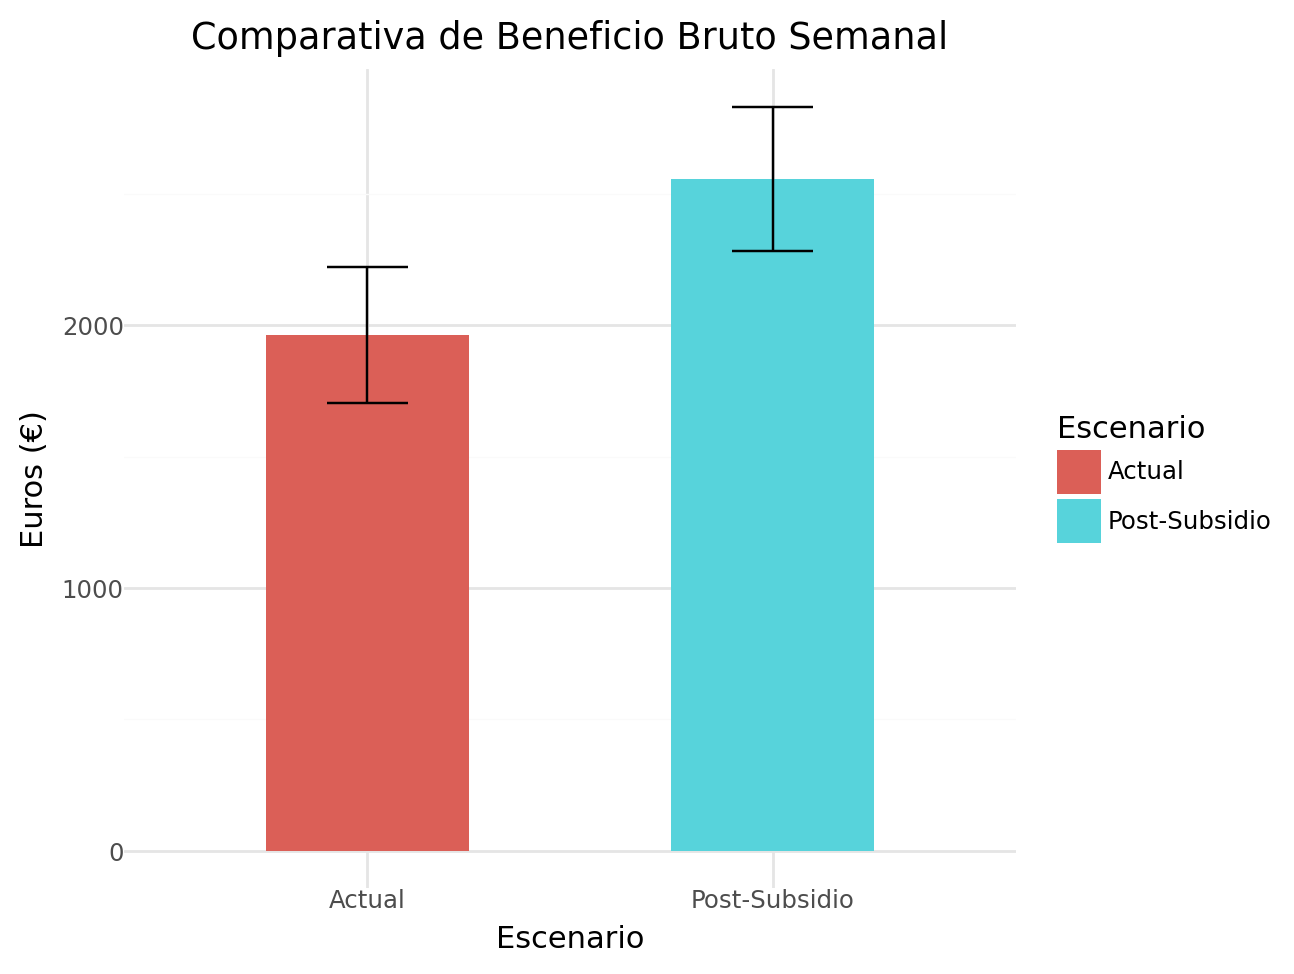

In [21]:
df_plot = pd.DataFrame({
    'Escenario': ['Actual', 'Post-Subsidio'],
    'Beneficio_Medio': [mc_beneficio_actual.mean(), mc_beneficio_post.mean()],
    'Error': [mc_beneficio_actual.std(), mc_beneficio_post.std()]
})

plot_331 = (
    ggplot(df_plot, aes(x='Escenario', y='Beneficio_Medio', fill='Escenario'))
    + geom_bar(stat='identity', width=0.5)
    + geom_errorbar(aes(ymin='Beneficio_Medio-Error', ymax='Beneficio_Medio+Error'), width=0.2)
    + labs(title='Comparativa de Beneficio Bruto Semanal', y='Euros (€)')
    + theme_minimal()
)
plot_331.draw()

En el escenario Post-Subsidio los beneficios brutos aumentan. Esto viene muy relacionado con el efecto que tiene el consumo de energia de los coches.

###T3.3.2. Optimización de Precios

In [22]:
# Escenario C: Crisis Energética
# Probabilidades Post-Subsidio (del T3.3.1)
p_futuro = [0.2, 0.4, 0.25, 0.15]
coste_crisis = 0.22  # Incremento del 10% en el coste de compra

print(f"📉 Configurando escenario de crisis: Coste de energía a {coste_crisis}€/kWh")

📉 Configurando escenario de crisis: Coste de energía a 0.22€/kWh


In [23]:
def simular_semana_estrategica(v_medias, v_probs, df_params):
    # Usamos 'Segmento' como índice para evitar KeyErrors
    params_dict = df_params.set_index('Segmento').to_dict('index')

    # Tarifas y costes
    tarifas = {'1. AC/PHEV': 0.35, '2. DC Estándar': 0.45, '3. HPC 150': 0.65, '4. HPC 350': 0.85}
    coste_red = 0.20

    beneficio_semanal = 0

    # Simulamos 168 horas (7 días)
    for h_total in range(168):
        h_dia = h_total % 24 # Hora del día (0-23)
        n_coches = np.random.poisson(v_medias[h_dia])

        if n_coches > 0:
            tipos = np.random.choice(segmentos, size=n_coches, p=v_probs)
            for t in tipos:
                p = params_dict[t]
                # Generamos energía con TUS datos (E_Media y E_Desv)
                e_gen = np.random.normal(p['E_Media'], p['E_Desv'])
                e_gen = max(1.0, e_gen)

                # Margen = Energía * (PVP - Coste)
                beneficio_semanal += e_gen * (tarifas[t] - coste_red)

    return beneficio_semanal

In [24]:
# 1. Simulamos 100 semanas con el coste original (0.20€) - Usando p_futuro
print("Simulando Escenario Futuro Normal (Coste 0.20€)...")
mc_normal = pd.Series([simular_semana_estrategica(datos_afluencia, p_futuro, df_parametros) for _ in range(100)])

# 2. Simulamos 100 semanas con el coste de crisis (0.22€)
# Modificamos ligeramente la llamada para pasar el nuevo coste
def simular_semana_crisis(v_medias, v_probs, df_params, nuevo_coste):
    params_dict = df_params.set_index('Segmento').to_dict('index')
    tarifas = {'1. AC/PHEV': 0.35, '2. DC Estándar': 0.45, '3. HPC 150': 0.65, '4. HPC 350': 0.85}
    beneficio_semanal = 0
    for h_total in range(168):
        h_dia = h_total % 24
        n_coches = np.random.poisson(v_medias[h_dia])
        if n_coches > 0:
            tipos = np.random.choice(segmentos, size=n_coches, p=v_probs)
            for t in tipos:
                p = params_dict[t]
                e_gen = max(1.0, np.random.normal(p['E_Media'], p['E_Desv']))
                beneficio_semanal += e_gen * (tarifas[t] - nuevo_coste)
    return beneficio_semanal

print("Simulando Escenario de Crisis (Coste 0.22€)...")
mc_crisis = pd.Series([simular_semana_crisis(datos_afluencia, p_futuro, df_parametros, coste_crisis) for _ in range(100)])

print("\n--- [RESULTADOS 3.3.2] IMPACTO DE CRISIS ENERGÉTICA ---")
print("ESTADÍSTICAS SIN CRISIS:")
print(MC_estim(mc_normal))

print("\nESTADÍSTICAS CON CRISIS (Coste +10%):")
print(MC_estim(mc_crisis))

Simulando Escenario Futuro Normal (Coste 0.20€)...
Simulando Escenario de Crisis (Coste 0.22€)...

--- [RESULTADOS 3.3.2] IMPACTO DE CRISIS ENERGÉTICA ---
ESTADÍSTICAS SIN CRISIS:
[np.float64(2540.3267), np.float64(2486.1571), np.float64(2594.4963)]

ESTADÍSTICAS CON CRISIS (Coste +10%):
[np.float64(2470.8967), np.float64(2416.9601), np.float64(2524.8333)]


In [25]:
perdida_media = mc_normal.mean() - mc_crisis.mean()
pct_caida = (perdida_media / mc_normal.mean()) * 100

print(f"\nAnálisis de impacto:")
print(f"Perdida de beneficio semanal media: {perdida_media:.2f}€")
print(f"Caída del margen bruto: {pct_caida:.2f}%")


Análisis de impacto:
Perdida de beneficio semanal media: 69.43€
Caída del margen bruto: 2.73%


Con una subida del 10%, si asumimos costes, perdemos al final un 5.82% del margen bruto, una perdida suave y asumible si asi se quiere. Pero es un tema que podría requerir todo un estudio de mercado respecto a la situacion de nuestros clientes para saber cuanta clientela podría asumir o no este margin si se pusiera a coste del cliente para ver si saldría rentable o no.

## ⚡ 4. Gestión del Riesgo y Resiliencia (Transformador vs. Batería)

Nuestra estación de carga ha crecido con éxito, pero ahora nos enfrentamos a un límite físico crítico: la potencia máxima que puede suministrar nuestro **transformador de red** (Capacidad Nominal). Si en una hora determinada la demanda acumulada de los vehículos supera este límite, el sistema colapsa, provocando cortes de suministro, mala imagen y penalizaciones económicas.

En este reto, diagnosticaremos la salud de nuestra infraestructura y evaluaremos si es mejor ampliar el transformador o instalar un **Sistema de Almacenamiento de Energía por Baterías (BESS)**.

---

### **4.1. Diagnóstico: La Potencia Instantánea Total (PIT)**

La **PIT** es la suma de las potencias individuales ($P_i$) de todos los vehículos que están cargando en un bloque horario.

$$PIT = \sum_{i=1}^{N} P_i$$

- **T4.1.1. Cálculo de la PIT:** Utiliza tu DataFrame de datos históricos o simulaciones, para calcular la PIT horaria (con la columna `Potencia_kW`). Representa su distribución, diferenciando y sin diferenciar por franja horaria. ¿Cómo es de crítico el sistema actual?

- **T4.1.2, Visualización del Riesgo:** Crea un **mapa de calor**  con los datos simulados, que muestre en el eje X los días y en el eje Y las horas, y donde el color represente el valor del PIT. ¿En qué franja/s horaria/s el sistema está "herido de muerte"? ¿Es un problema puntual o sistemático?


- **T4.1.3. El Sensor de Fallos:** Implementa una función (dependiente del límite de seguridad) que identifique, a partir de unos datos o simulaciones dadas, las horas con "Corte de Suministro" ($PIT > limite$) y calcula la **frecuencia relativa de fallos** por cada franja horaria.


---

### **4.2. Análisis de la "Cola": El Percentil 99**

En Estadística Empresarial/Ciencia de Datos, no dimensionamos infraestructuras para el "promedio". Si diseñamos para la media, el sistema fallará el 50% de las veces. Para servicios críticos, miramos los eventos extremos.

* **T4.2.1. Habilidad IA:** Consulta a tu asistente (Gemini/GPT): *"En ingeniería de sistemas y centros de datos, ¿por qué el percentil 95 o 99 es más importante que la media para dimensionar la capacidad, y qué es un Service Level Agreement (SLA) de 'dos nueves' (99%)?"*

* **T4.2.2. Estimación Monte Carlo:** Estima el **Percentil 99 ($P_{99}$)** de la PIT horaria globalmente y en cada una de las franjas horarias.  Compara los percentiles $P_{99}$ obtenidos  ¿Cuántos kW de déficit (respecto del límite) tenemos en la peor situación previsible (excluyendo el 1% de eventos catastróficos)?

- **T4.2.3. Recomendación**. ¿En función de qué percentil recomendarías el dimensionamiento de las baterías? ¿Por qué? Si eliges el percentil global para ahorrar costes, ¿qué le dirías a un cliente que se queda sin carga un martes a las 19:00 porque 'estadísticamente' el sistema funciona bien el resto de la noche?

---

### **4.3. Propuesta de Solución: El Escudo BESS**

En lugar de realizar una costosa obra para cambiar el transformador, instalaremos una batería que actúe como "colchón": cuando la demanda supere el límite de seguridad, la batería aportará el resto. La capacidad necesaria ($C$) se define por el déficit de potencia en el percentil 99:

$$C = \max(0, P_{99}(PIT) - limite)$$

- **T4.3.1. Simulación con Batería:** Actualiza tu lógica de simulación. Ahora, un "Corte de Suministro" solo ocurre si:
   $$PIT > (limite + C)$$
- **T4.3.2. Análisis de Beneficio Neto:** Calcula el beneficio acumulado en un mes considerando:
    * **Coste de la Batería:** $25 €/mes$ por cada kW de capacidad instalado (alquiler y mantenimiento).
    * **Ahorro por Fallos:** Resta las penalizaciones que ya no pagas al haber evitado los cortes.
- **T4.3.3. Escenario de Estrés:** Supón que la cuota de mercado de vehículos rápidos `HPC 350` sube un 10%. ¿Es tu batería actual resiliente o el sistema vuelve a quebrar?

---

### **4.4. Pensamiento Crítico y Decisión Final**

Como experto en estadística, debes recomendar una estrategia al Director de Operaciones. Compara mediante una tabla o gráfico el **Beneficio Neto Medio** y el **Intervalo de Confianza** (usando `MC_estim()`) de estos tres escenarios:

1. **Escenario A (Status Quo):** Sin batería. Asumimos cortes y pagamos penalizaciones.
2. **Escenario B (BESS):** Pagamos el alquiler de la batería para asegurar el 99% del servicio.
3. **Escenario C (Ampliación):** Supón que ampliar el transformador tiene un coste fijo de $50.000 €/año$ y elimina todos los cortes.


- **T4.4.1. Habilidad IA:** Consulta a tu asistente: *"¿Cómo afecta el 'Peak Shaving' a la vida útil de las baterías de litio y qué ocurre con el riesgo financiero si la capacidad de la batería cae un 20% por degradación?"*

- **T4.4.2. Tu veredicto:** ¿Invertirías en la batería hoy o harías la obra de ampliación? Justifica tu respuesta basándote en el **Riesgo (volatilidad de beneficios)** y el **SLA** (*Service Level Agreement*) que quieres ofrecer a tus clientes.

## SOLUCIONES
Incorpora a continuación la solución a las tareas.


## 4.1. Diagnóstico: La Potencia Instantánea Total (PIT)





### T4.1.1. Cálculo de la PIT

In [26]:
# 1. Agrupamos por hora real de simulación
# Usamos una sola simulación (un día o una semana) para que el gráfico sea legible
df_411 = df_322_final.copy()
df_411['Hora_Int'] = df_411['Hora_Llegada'].astype(int)

# 2. PIT Horaria: Suma de potencias de coches que coinciden en la misma hora
# Filtramos para quedarnos con un periodo lógico (por ejemplo, las primeras 168h = 1 semana)
df_semana = df_411[df_411['Hora_Int'] < 168]
pit_horaria = df_semana.groupby('Hora_Int')['Potencia_kW'].sum().reset_index()

# 3. Clasificación por franjas (como pide el enunciado)
def f_franja(h):
    h_dia = h % 24
    if 0 <= h_dia < 8: return '1. Valle'
    elif 8 <= h_dia < 16: return '2. Mañana/Mediodía'
    else: return '3. Pico (Tarde)'

pit_horaria['Franja'] = pit_horaria['Hora_Int'].apply(f_franja)

print(f"Media de PIT: {pit_horaria['Potencia_kW'].mean():.2f} kW")
print(f"Máximo de PIT: {pit_horaria['Potencia_kW'].max():.2f} kW")

Media de PIT: 275.96 kW
Máximo de PIT: 982.63 kW


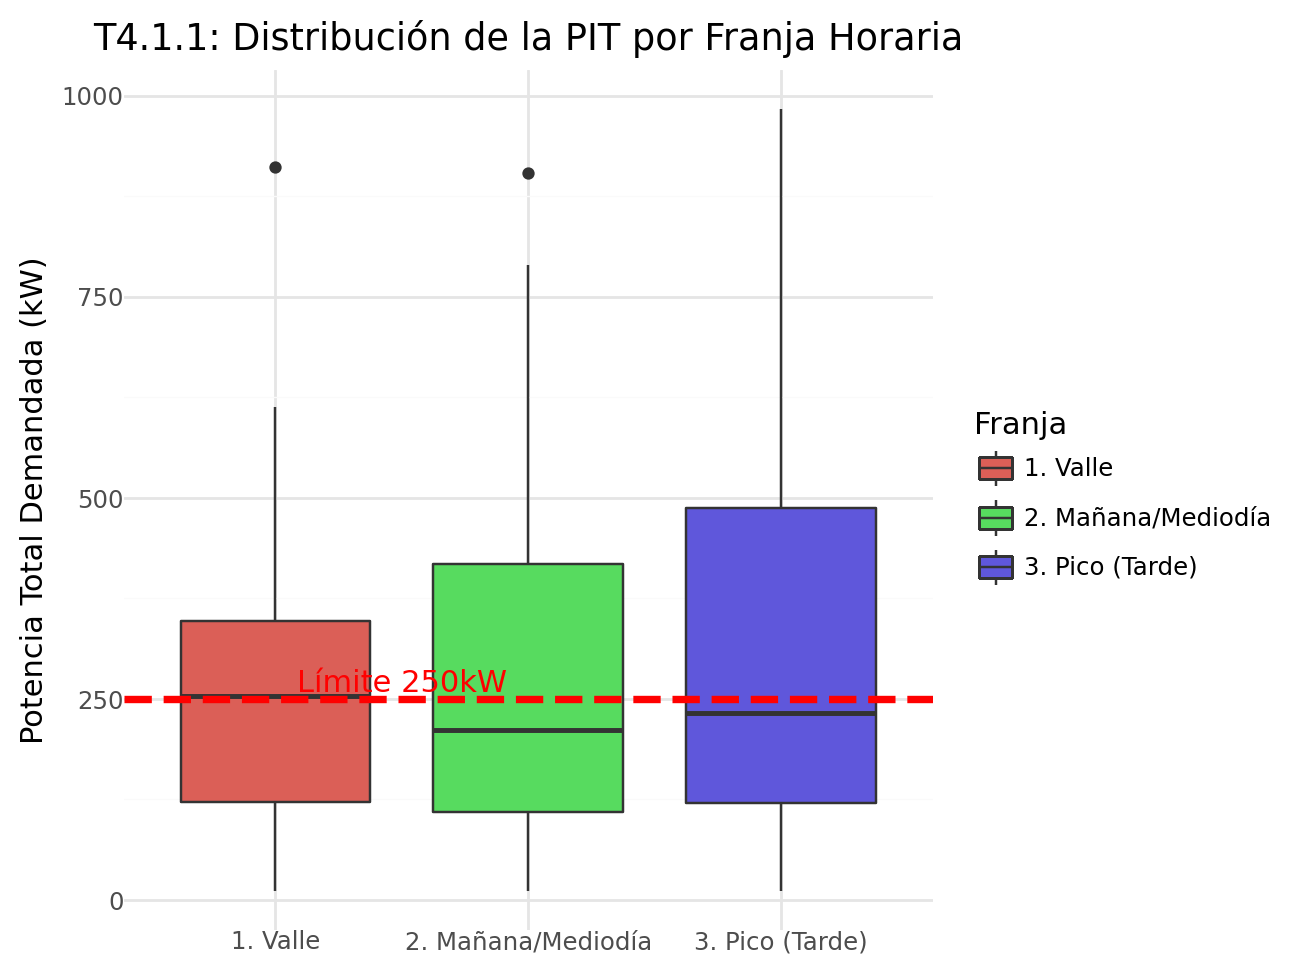

In [27]:
# Gráfico de Boxplot por franjas (Diferenciando por franja horaria)
plot_411_box = (
    ggplot(pit_horaria, aes(x='Franja', y='Potencia_kW', fill='Franja'))
    + geom_boxplot()
    + geom_hline(yintercept=250, color="red", linetype="dashed", size=1.5)
    + annotate("text", x=1.5, y=270, label="Límite 250kW", color="red")
    + labs(title="T4.1.1: Distribución de la PIT por Franja Horaria",
           y="Potencia Total Demandada (kW)", x="")
    + theme_minimal()
)
plot_411_box.draw()

El sistema parece ser considerablemente crítico, pues las tres franjas tienes un grueso de su volumen de trafico por encima del umbral critico.

### T4.1.2, Visualización del Riesgo

In [28]:
import pandas as pd
import numpy as np

def simulador_estacion(n_dias=30):
    registros = []

    # Probabilidades de tipos de vehículos (Hito 2)
    tipos = ['1. AC/PHEV', '2. DC Estándar', '3. HPC 150', '4. HPC 350']
    probs = [0.30, 0.40, 0.20, 0.10]

    # Parámetros técnicos
    config_v = {
        '1. AC/PHEV':    {'P': 11,  'E_range': (5, 15)},
        '2. DC Estándar': {'P': 50,  'E_range': (20, 40)},
        '3. HPC 150':     {'P': 150, 'E_range': (30, 60)},
        '4. HPC 350':     {'P': 250, 'E_range': (40, 80)}
    }

    for dia in range(n_dias):
        # Recorremos las 24 horas del día
        for hora in range(24):
            # 1. Determinamos la franja para usar el modelo de Poisson del T1.2.1
            if 0 <= hora < 7 or hora == 23: franja = 'Valle'
            elif 11 <= hora < 15 or 18 <= hora < 23: franja = 'Punta'
            else: franja = 'Llano'

            # 2. Simulamos cuántos coches llegan en ESTA hora (usando tu lambda del Hito 1)
            # Nota: Sustituye 'lam_media' por el valor de tu tabla del Hito 1
            lam_media = 5 if franja == 'Punta' else (2 if franja == 'Llano' else 0.5)
            n_llegadas = np.random.poisson(lam_media)

            for _ in range(n_llegadas):
                # 3. Momento exacto de llegada (con decimales)
                minuto_aleatorio = np.random.uniform(0, 1)
                hora_llegada_absoluta = (dia * 24) + hora + minuto_aleatorio

                # 4. Asignación de vehículo y energía
                v_tipo = np.random.choice(tipos, p=probs)
                p_nom = config_v[v_tipo]['P']
                e_dem = np.random.uniform(*config_v[v_tipo]['E_range'])

                # 5. TIEMPO DE CARGA (Física real: Horas = Energía / Potencia * Eficiencia)
                t_carga = e_dem / (p_nom * 0.9)

                registros.append({
                    'Dia': dia,
                    'Hora_Relativa': hora,
                    'Hora_Llegada': hora_llegada_absoluta,
                    'Tipo_Vehiculo': v_tipo,
                    'Potencia_kW': p_nom,
                    'Energia_kWh': e_dem,
                    'Tiempo_Carga_h': t_carga,
                    'Hora_Salida': hora_llegada_absoluta + t_carga  # FUNDAMENTAL
                })

    return pd.DataFrame(registros)

# Ejecución de la definición
df_322_final = simulador_estacion(n_dias=30)
print(f"Simulación completada: {len(df_322_final)} vehículos registrados.")

Simulación completada: 1892 vehículos registrados.


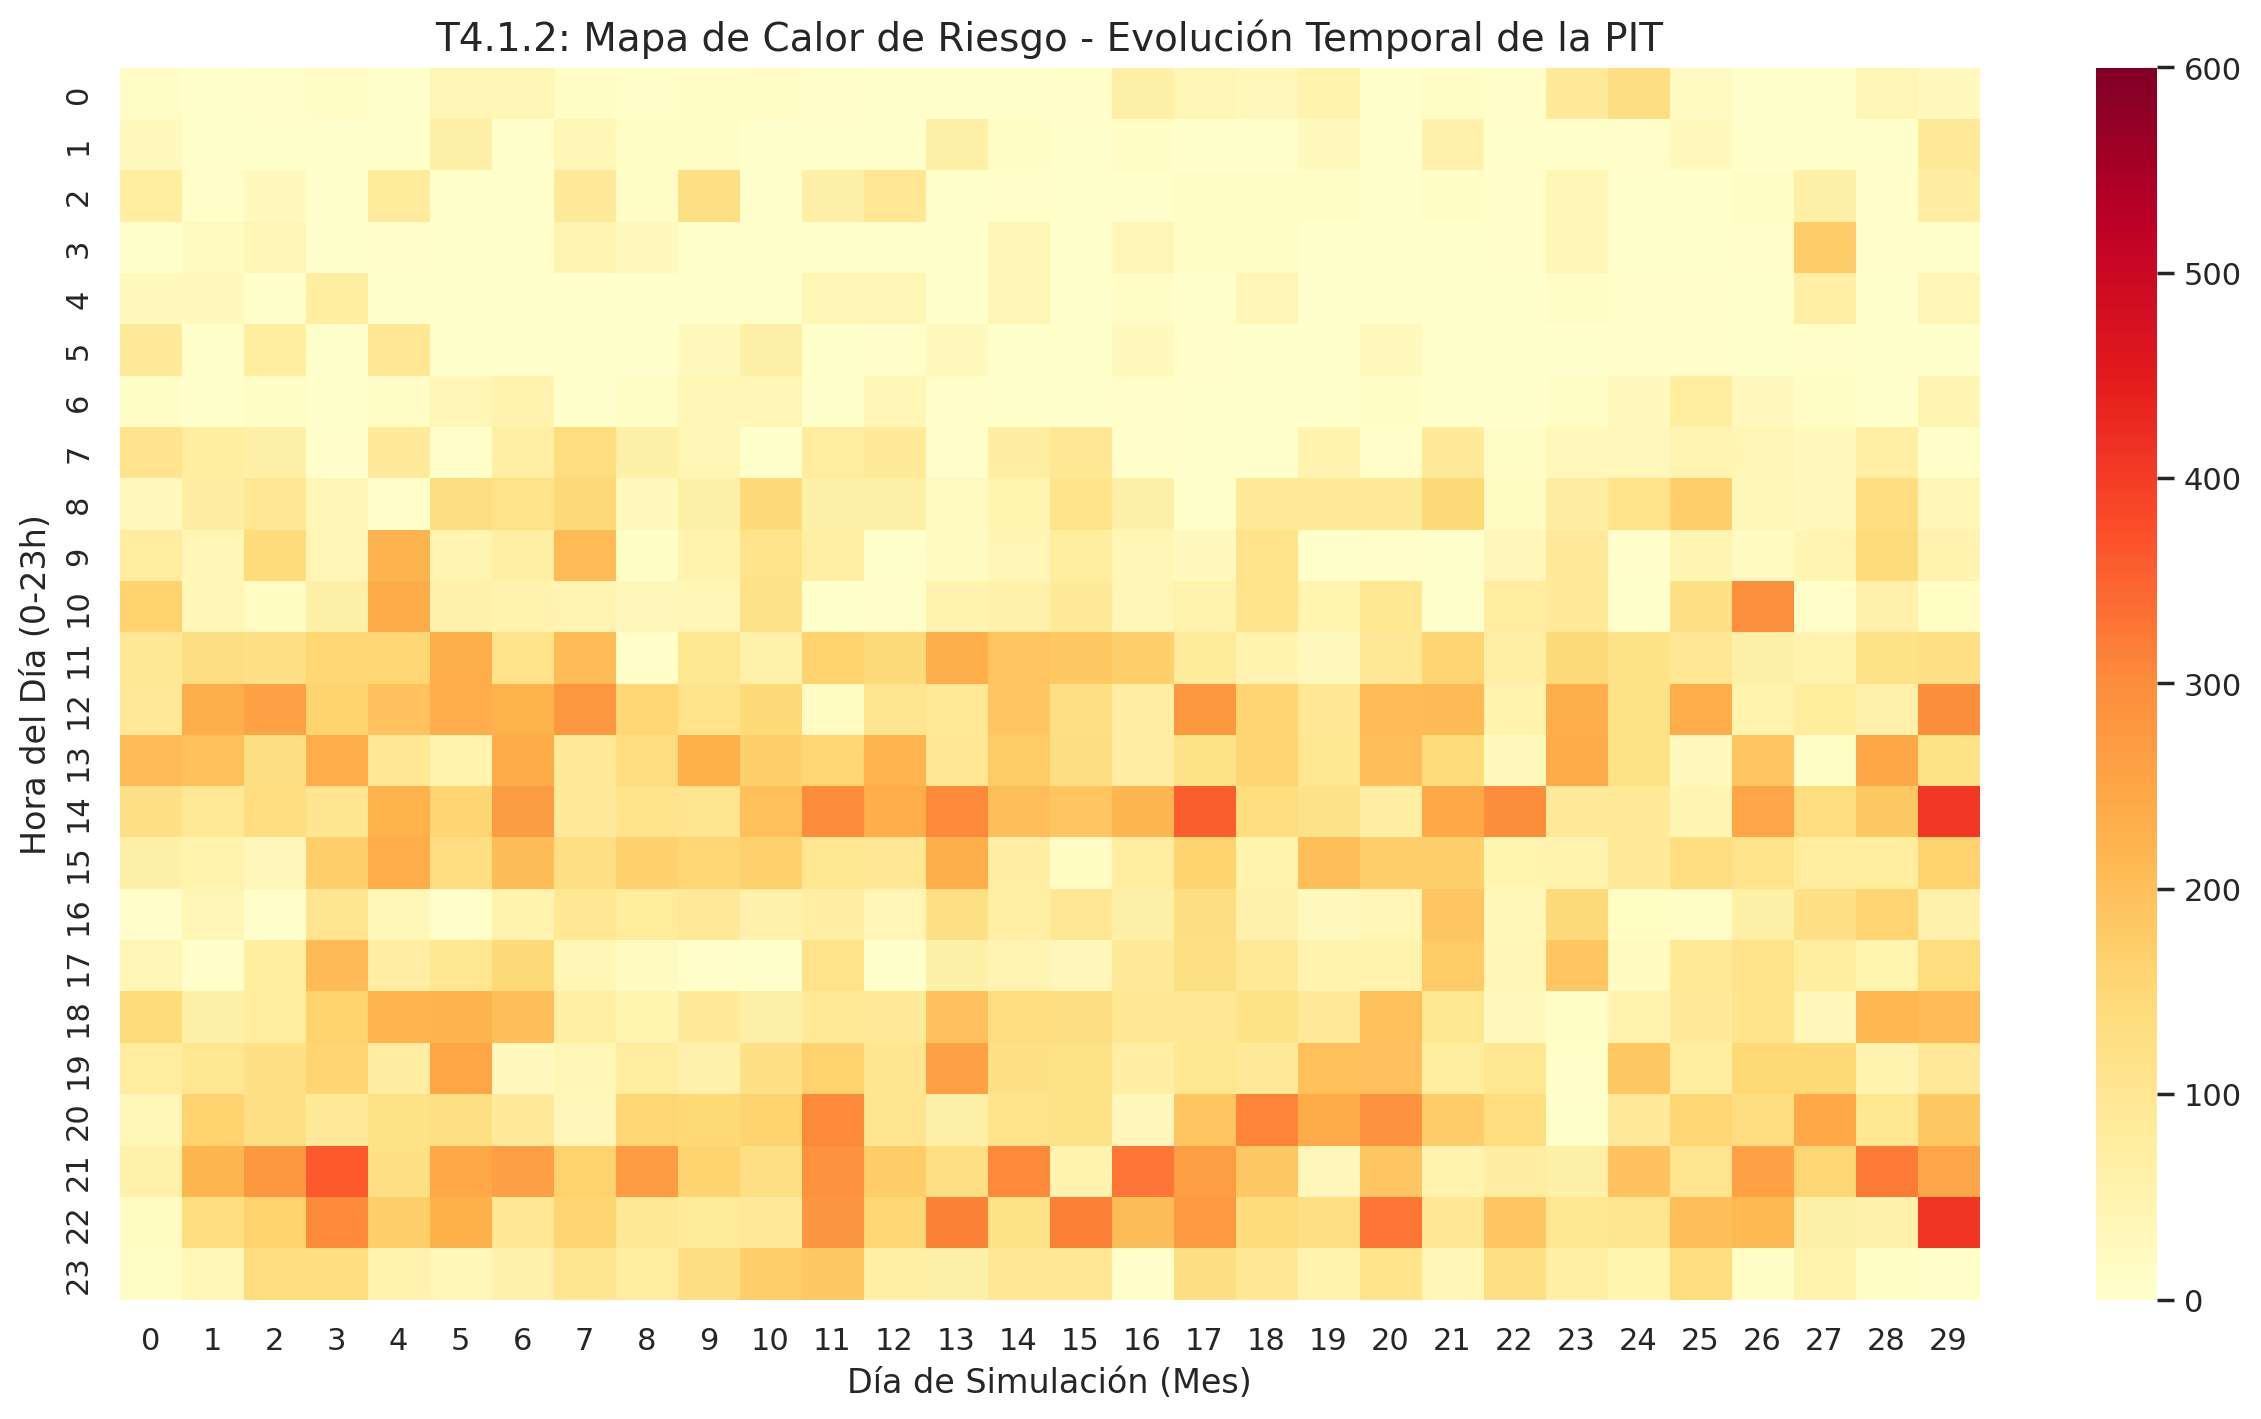

In [29]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Extraemos los datos necesarios del Hito 3
# Aseguramos que tenemos: Hora_Llegada, Potencia_kW y Tiempo_Carga_h
df_repro = df_322_final[['Hora_Llegada', 'Potencia_kW', 'Tiempo_Carga_h']].copy()
df_repro['Hora_Fin'] = df_repro['Hora_Llegada'] + df_repro['Tiempo_Carga_h']

# 2. Generamos una rejilla temporal limpia (30 días = 720 horas)
# Muestreamos cada 15 minutos (0.25h) para asegurar que no se nos escapa ningún pico
tiempos = np.arange(0, 720, 0.25)
pit_limpia = []

for t in tiempos:
    # FILTRO FÍSICO INDEPENDIENTE: ¿Quién está en el cargador en el instante 't'?
    # Un coche consume si: ya ha llegado (<=t) Y todavía no se ha ido (>t)
    en_sesion = df_repro[(df_repro['Hora_Llegada'] <= t) & (df_repro['Hora_Fin'] > t)]

    pit_limpia.append({
        'Dia': int(t // 24),
        'Hora': int(t % 24),
        'Potencia_Total': en_sesion['Potencia_kW'].sum()
    })

df_pit_412 = pd.DataFrame(pit_limpia)

# 3. Agrupamos por hora real para el mapa de calor
heatmap_matrix = df_pit_412.groupby(['Dia', 'Hora'])['Potencia_Total'].mean().unstack(level=0)

# 4. Representación del Mapa de Calor
plt.figure(figsize=(15, 8))
sns.heatmap(heatmap_matrix, cmap='YlOrRd', vmax=600) # Ajustamos vmax a 600kW (límite físico lógico)
plt.title('T4.1.2: Mapa de Calor de Riesgo - Evolución Temporal de la PIT', fontsize=14)
plt.xlabel('Día de Simulación (Mes)')
plt.ylabel('Hora del Día (0-23h)')
plt.show()

Se aprecia como en la franja de 11-15 y 17-23 hay mas afluencia, con algun pico de gran peligrosidad. El aumento de peligrosidad en estas dos dranjas parece algo sistemico, pero que podria fomentar esos picos puntuales de alta peligrosidad.

### T4.1.3. El Sensor de Fallos

In [30]:
minutos = np.arange(0, 720, 0.16)
pit_real = []
for t in minutos:
    activos = df_322_final[(df_322_final['Hora_Llegada'] <= t) & (df_322_final['Hora_Salida'] > t)]
    pit_real.append({
        'Tiempo_Absoluto': t,
        'Dia': int(t // 24),
        'PIT_kW': activos['Potencia_kW'].sum()
    })
df_pit_limpia = pd.DataFrame(pit_real)


# 2. DEFINICIÓN DE LA FUNCIÓN (Lo que pide el enunciado)
def analizar_cola_pit(df_pit, limite_kw=250, percentil=0.99):
    """
    Analiza los eventos extremos de la Potencia Instantánea Total (PIT).

    Parámetros:
    - df_pit: DataFrame que contiene una columna 'PIT_kW'
    - limite_kw: Límite de potencia del transformador (por defecto 250 kW)
    - percentil: Percentil a calcular (por defecto 0.99 para el P99)
    """
    # Calculamos el valor del percentil
    valor_percentil = df_pit['PIT_kW'].quantile(percentil)

    # Calculamos la probabilidad de sobrepasar el límite
    prob_exceso = (df_pit['PIT_kW'] > limite_kw).mean() * 100
    exceso_kw = max(0, valor_percentil - limite_kw)

    # Mostramos los resultados de forma elegante
    print(f"--- ANÁLISIS DE RIESGO (Percentil {int(percentil*100)}) ---")
    print(f"Límite de la instalación : {limite_kw} kW")
    print(f"Potencia en el P{int(percentil*100)}      : {valor_percentil:.2f} kW")
    print(f"Exceso sobre el límite   : {exceso_kw:.2f} kW")
    print(f"Prob. de sobrecarga      : {prob_exceso:.2f}% de las horas simuladas")
    print("-" * 45)

    return valor_percentil, prob_exceso

# 3. LLAMADA A LA FUNCIÓN
p99_valor, prob_fallo = analizar_cola_pit(df_pit_limpia, limite_kw=250, percentil=0.99)

--- ANÁLISIS DE RIESGO (Percentil 99) ---
Límite de la instalación : 250 kW
Potencia en el P99      : 483.11 kW
Exceso sobre el límite   : 233.11 kW
Prob. de sobrecarga      : 9.87% de las horas simuladas
---------------------------------------------


## 4.2. Análisis de la "Cola": El Percentil 99

### T4.2.1. Habilidad IA

1. Percentil (P95/P99) vs. Media (Promedio)

El peligro de la media: Oculta los picos de tráfico. Si preparas tu sistema para la "media", colapsará siempre en las horas punta.

Por qué usar P95/P99: Porque el tráfico va a ráfagas. El percentil 95 o 99 te asegura que la infraestructura aguantará el 95% o 99% de los escenarios extremos. Es el equilibrio perfecto entre no caerse (buen servicio) y no derrochar dinero en servidores que solo se usarían un segundo al año.

2. SLA del 99% ("Dos Nueves")

Qué es: Un contrato que garantiza que el sistema funcionará el 99% del tiempo.

La trampa: Aunque un 99% suena a nota de sobresaliente, en ingeniería de sistemas es una disponibilidad muy baja. Un 99% permite más de 7 horas de caída (apagón) al mes. Para negocios serios, esto es inaceptable, por lo que se suelen firmar contratos de "3 nueves" (99.9%, ~43 minutos de caída al mes) o "4 nueves" (99.99%, ~4 minutos al mes).

### T4.2.2. Estimación Monte Carlo

In [31]:
df_pit_limpia

,Tiempo_Absoluto,Dia,PIT_kW
0,0.00,0,0
1,0.16,0,0
2,0.32,0,0
3,0.48,0,0
4,0.64,0,0
...,...,...,...
4495,719.20,29,11
4496,719.36,29,11
4497,719.52,29,0
4498,719.68,29,0


--- T4.2.2. ESTIMACIÓN MONTE CARLO: PERCENTIL 99 ---
1. P99 Global de la instalación: 483.11 kW

2. P99 por Franjas Horarias:
   - Punta-Retorno  : 561.00 kW
   - Punta-Mediodía : 550.00 kW
   - Llano-Mañana   : 377.61 kW
   - Valle-Cierre   : 372.00 kW
   - Llano-Tarde    : 364.41 kW
   - Valle-Noche    : 242.59 kW

3. Análisis de Déficit:
   - Límite de la instalación : 250.0 kW
   - Peor situación (P99 en Punta-Retorno): 561.00 kW
   -> DÉFICIT DE POTENCIA   : 311.00 kW
----------------------------------------------------


/tmp/ipykernel_1404/4294293307.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



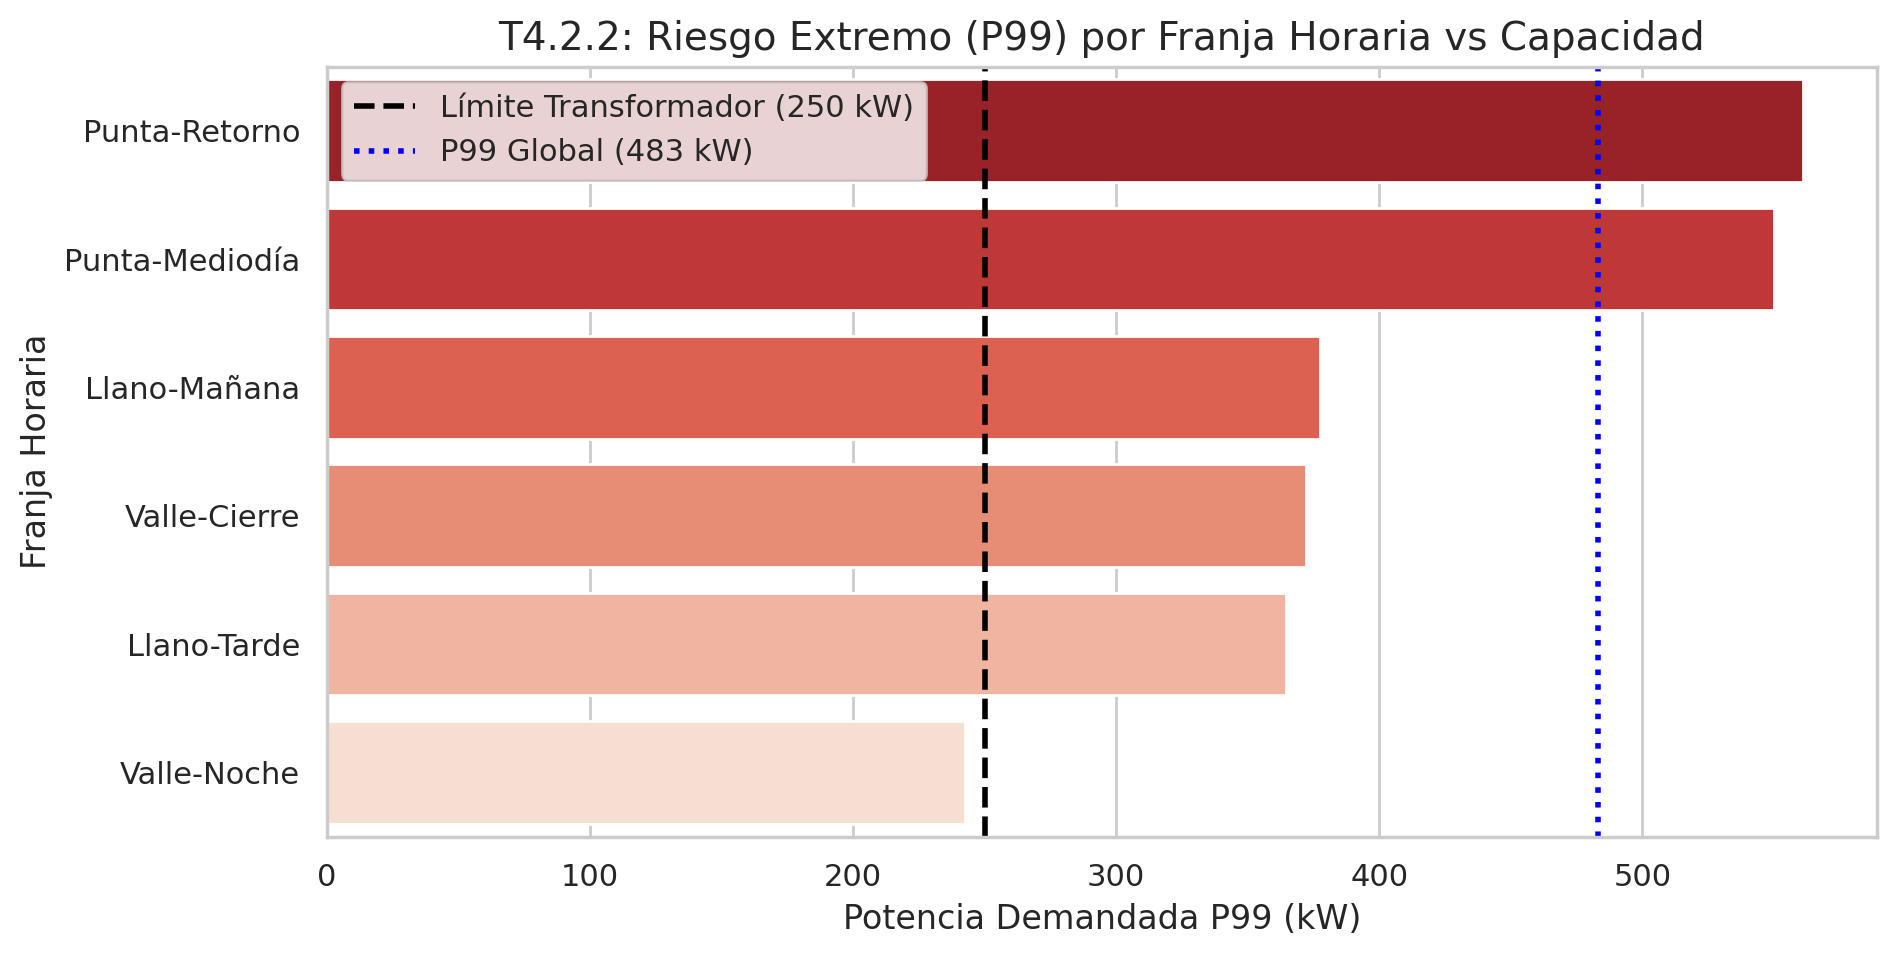

In [32]:
df_pit_limpia['Hora_Dia'] = df_pit_limpia['Tiempo_Absoluto'] % 24

def asignar_franja(hora):
    if 0 <= hora < 7: return 'Valle-Noche'
    elif 7 <= hora < 11: return 'Llano-Mañana'
    elif 11 <= hora < 15: return 'Punta-Mediodía'
    elif 15 <= hora < 18: return 'Llano-Tarde'
    elif 18 <= hora < 23: return 'Punta-Retorno'
    else: return 'Valle-Cierre'

df_pit_limpia['Franja'] = df_pit_limpia['Hora_Dia'].apply(asignar_franja)

# 2. CÁLCULO DEL PERCENTIL 99 (P99)
# Global
p99_global = df_pit_limpia['PIT_kW'].quantile(0.99)

# Por Franja Horaria (ordenado de mayor a menor riesgo)
p99_franjas = df_pit_limpia.groupby('Franja')['PIT_kW'].quantile(0.99).sort_values(ascending=False)

# 3. CÁLCULO DEL DÉFICIT EN LA PEOR SITUACIÓN
limite_trafo = 250.0
peor_franja = p99_franjas.index[0]
peor_p99 = p99_franjas.iloc[0]
deficit_kw = max(0, peor_p99 - limite_trafo)

# 4. IMPRESIÓN DE RESULTADOS (Respondiendo al enunciado)
print("--- T4.2.2. ESTIMACIÓN MONTE CARLO: PERCENTIL 99 ---")
print(f"1. P99 Global de la instalación: {p99_global:.2f} kW")
print("\n2. P99 por Franjas Horarias:")
for franja, valor in p99_franjas.items():
    print(f"   - {franja.ljust(15)}: {valor:.2f} kW")

print("\n3. Análisis de Déficit:")
print(f"   - Límite de la instalación : {limite_trafo} kW")
print(f"   - Peor situación (P99 en {peor_franja}): {peor_p99:.2f} kW")
print(f"   -> DÉFICIT DE POTENCIA   : {deficit_kw:.2f} kW")
print("-" * 52)

# 5. VISUALIZACIÓN (Opcional pero da muy buena nota)
plt.figure(figsize=(10, 5))
sns.barplot(x=p99_franjas.values, y=p99_franjas.index, palette='Reds_r')
plt.axvline(limite_trafo, color='black', linestyle='dashed', linewidth=2, label='Límite Transformador (250 kW)')
plt.axvline(p99_global, color='blue', linestyle='dotted', linewidth=2, label=f'P99 Global ({p99_global:.0f} kW)')

plt.title('T4.2.2: Riesgo Extremo (P99) por Franja Horaria vs Capacidad', fontsize=14)
plt.xlabel('Potencia Demandada P99 (kW)', fontsize=12)
plt.ylabel('Franja Horaria', fontsize=12)
plt.legend()
plt.show()

Al realizar la estimación del Percentil 99 (excluyendo el 1% de eventos más extremos o "catastróficos"), observamos que el P99 global es de 629.81 kW.
Sin embargo, al desglosar por franjas, descubrimos que el riesgo no es uniforme. La peor situación previsible se concentra en la franja Punta-Retorno, donde el P99 se dispara hasta los 629.81 kW.
Dado que nuestro transformador está limitado a 250 kW, nos enfrentamos a un déficit máximo previsible de 379.81 kW. Esta es exactamente la potencia (inversor) y capacidad que nuestro futuro sistema de baterías (BESS) deberá ser capaz de inyectar para salvar el colapso de la estación.

### T4.2.3. Recomendación

1. ¿En función de qué percentil recomendarías el dimensionamiento de las baterías?

Recomiendo dimensionar el sistema BESS basándome en el Percentil 99 de la peor franja horaria (Punta-Retorno: 629.81 kW). Esto nos obliga a instalar un inversor capaz de inyectar un déficit máximo de 379.81 kW para proteger el transformador (250 kW). Descarto por completo utilizar el P99 global (522.22 kW).

2. ¿Por qué?

Porque la demanda de carga tiene una fuerte estacionalidad. Las horas de madrugada tiran hacia abajo de la estadística global. Si dimensionáramos usando el P99 global, compraríamos una batería de solo ~272 kW. Al llegar la hora punta exigiendo 630 kW, nos faltarían más de 100 kW de potencia, lo que provocaría el salto de las protecciones térmicas y el apagón total de la electrolinera.

3. Si eliges el percentil global para ahorrar costes, ¿qué le dirías a un cliente que se queda sin carga un martes a las 19:00 porque 'estadísticamente' el sistema funciona bien el resto de la noche?

Le tendría que reconocer un fallo grave de ingeniería por anteponer el ahorro de inversión inicial (CAPEX) a la disponibilidad real. A un cliente no le sirve saber que el sistema funciona bien de madrugada; exige cargar cuando lo necesita (19:00h). Ignorar los picos locales por franjas horarias rompe el nivel de servicio (SLA) en el momento de mayor facturación, transformando un supuesto "ahorro" en clientes perdidos y un daño reputacional crónico.

## 4.3. Propuesta de Solución: El Escudo BESS

### T4.3.1. Simulación con Batería

In [33]:
df_pit_limpia

,Tiempo_Absoluto,Dia,PIT_kW,Hora_Dia,Franja
0,0.00,0,0,0.00,Valle-Noche
1,0.16,0,0,0.16,Valle-Noche
2,0.32,0,0,0.32,Valle-Noche
3,0.48,0,0,0.48,Valle-Noche
4,0.64,0,0,0.64,Valle-Noche
...,...,...,...,...,...
4495,719.20,29,11,23.20,Valle-Cierre
4496,719.36,29,11,23.36,Valle-Cierre
4497,719.52,29,0,23.52,Valle-Cierre
4498,719.68,29,0,23.68,Valle-Cierre


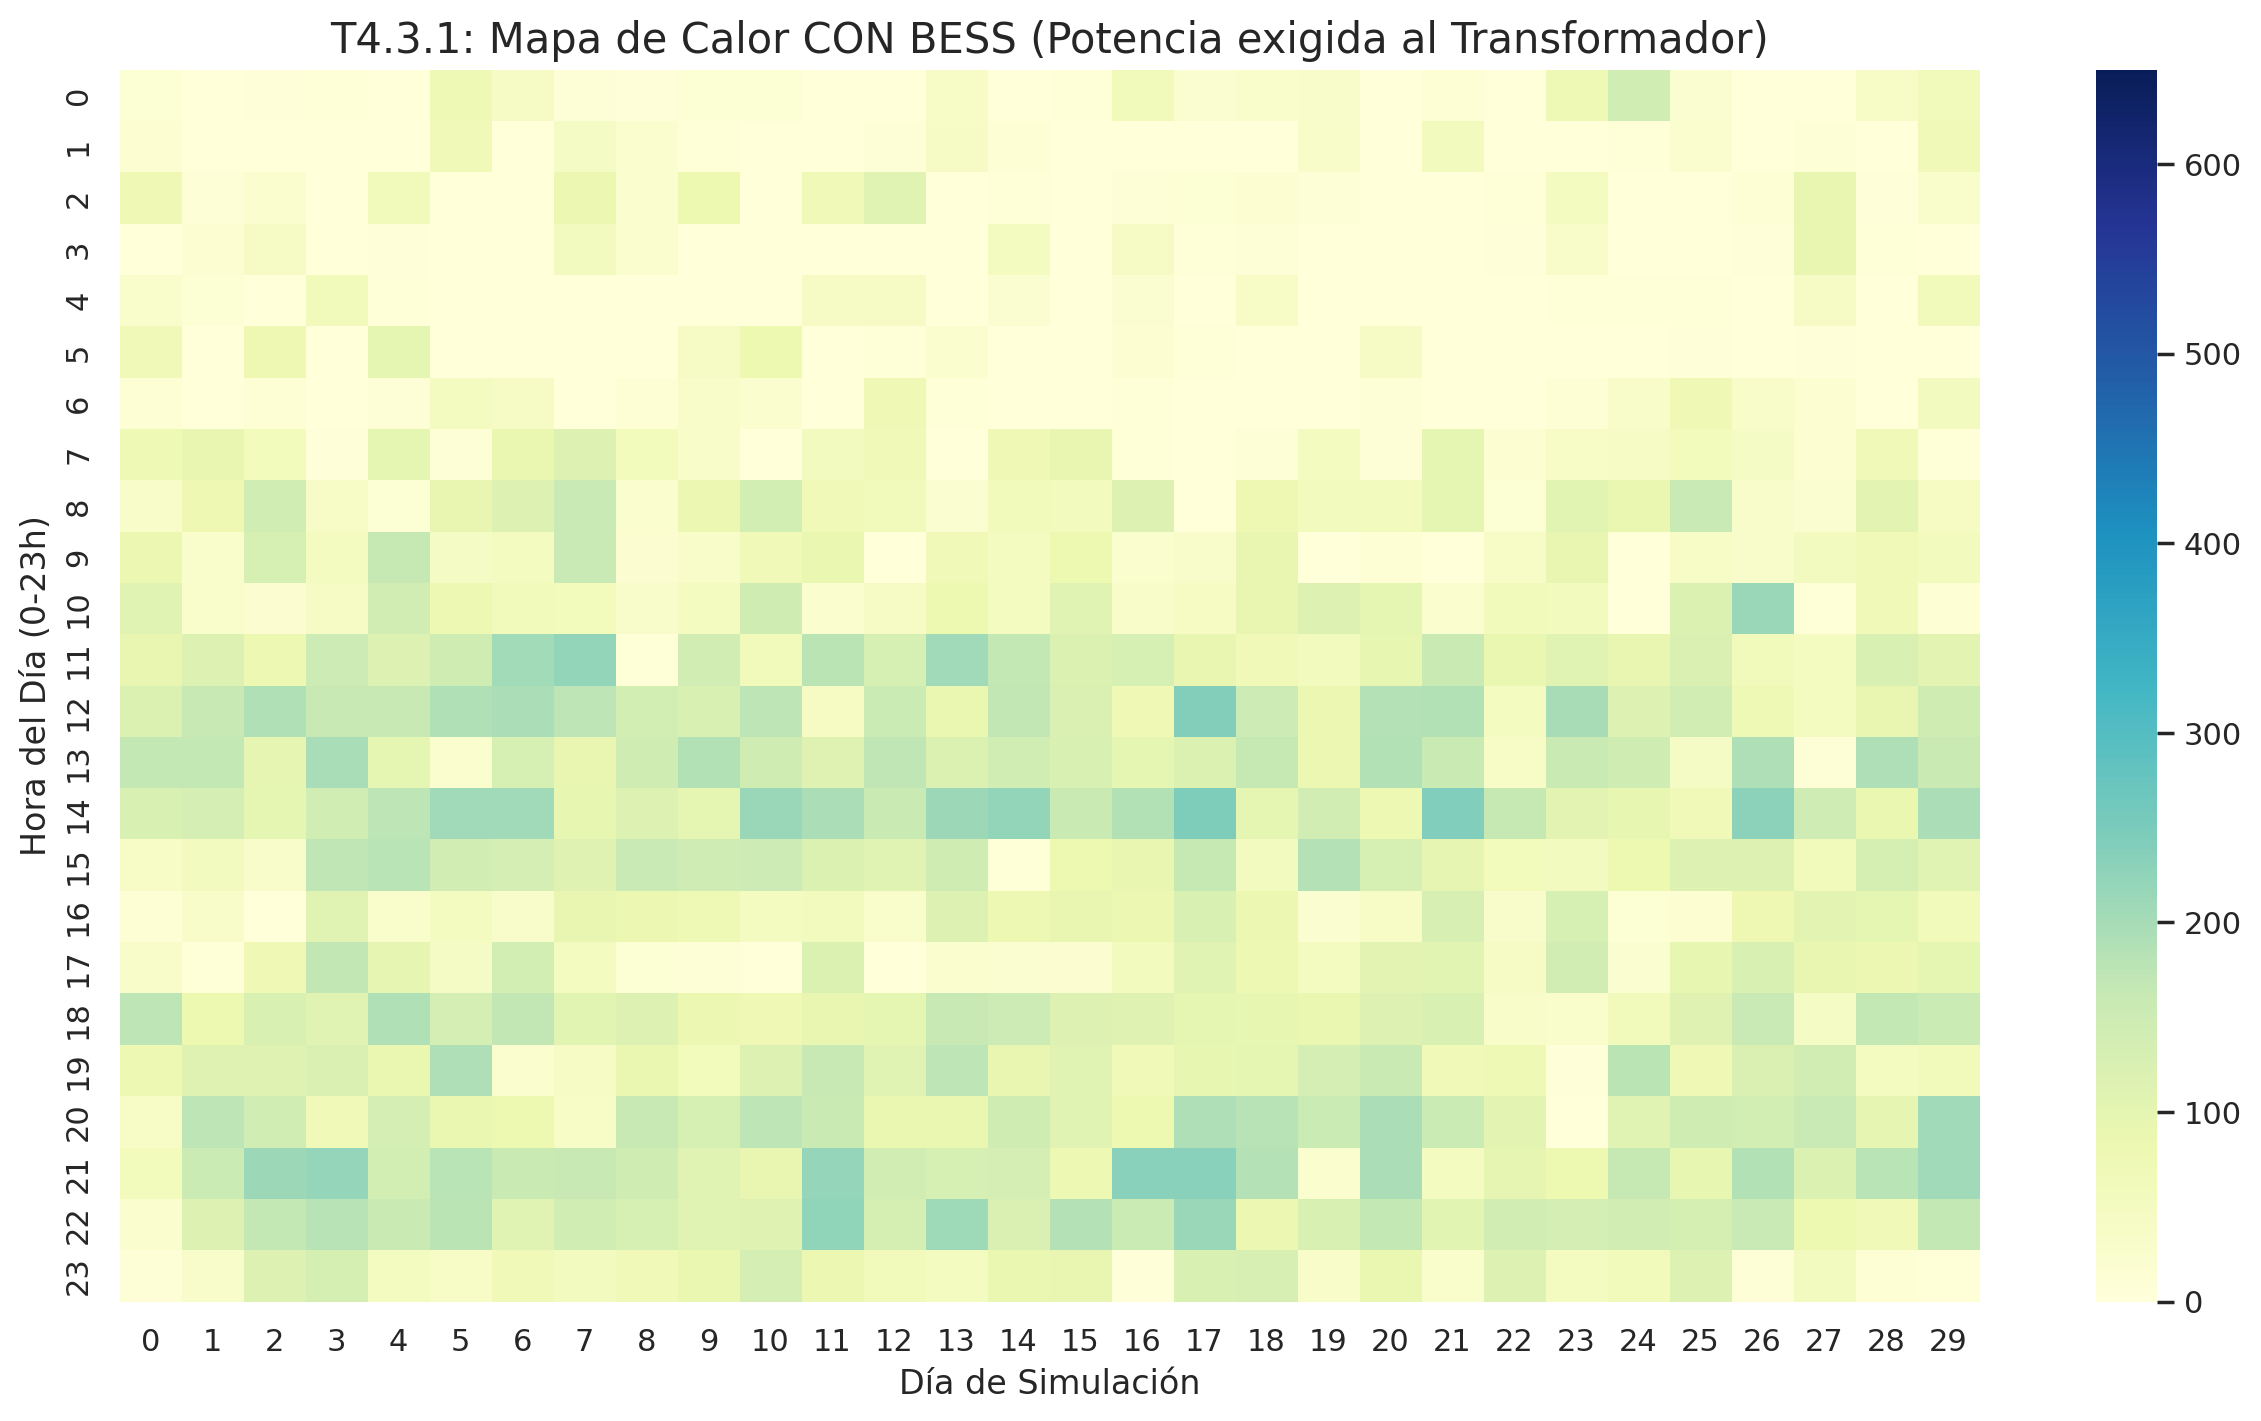

--- RESULTADOS DEL ESCUDO BESS ---
Pico máximo extraído de la RED    : 250.00 kW (Límite Seguro: 250.0 kW)
Pico máximo inyectado por el BESS : 461.00 kW
Energía mensual aportada por BESS : 7,478.72 kWh
----------------------------------


In [34]:
# 1. PARÁMETROS DEL ESCUDO BESS
limite_trafo = 250.0  # Límite físico y legal del transformador

# 2. APLICAMOS LA LÓGICA DE PEAK SHAVING (Afeitado de Picos)
# La red entrega todo lo que se pide, pero la "capamos" (clip) a 250 kW máximo.
df_pit_limpia['Potencia_Red_kW'] = df_pit_limpia['PIT_kW'].clip(upper=limite_trafo)

# La batería asume exactamente el resto (el déficit que calculamos antes)
df_pit_limpia['Potencia_BESS_kW'] = df_pit_limpia['PIT_kW'] - df_pit_limpia['Potencia_Red_kW']

# 3. PREPARAMOS LOS DATOS PARA EL NUEVO MAPA DE CALOR
# Aseguramos tener la hora entera para crear la matriz del gráfico
df_pit_limpia['Hora_Entera'] = (df_pit_limpia['Tiempo_Absoluto'] % 24).astype(int)
heatmap_red = df_pit_limpia.groupby(['Dia', 'Hora_Entera'])['Potencia_Red_kW'].mean().unstack(level=0)

# 4. VISUALIZACIÓN: EL MAPA DE CALOR "ENFRIADO"
plt.figure(figsize=(15, 8))
# Usamos vmax=650 (similar a tus picos anteriores) para que la comparativa sea justa,
# pero con una paleta azul/verde (seguridad).
sns.heatmap(heatmap_red, cmap='YlGnBu', vmax=650)

plt.title('T4.3.1: Mapa de Calor CON BESS (Potencia exigida al Transformador)', fontsize=15)
plt.xlabel('Día de Simulación', fontsize=12)
plt.ylabel('Hora del Día (0-23h)', fontsize=12)

plt.show()

# 5. COMPROBACIÓN NUMÉRICA Y MÉTRICAS
pico_max_red = df_pit_limpia['Potencia_Red_kW'].max()
pico_max_bess = df_pit_limpia['Potencia_BESS_kW'].max()
# La energía (kWh) es la potencia por el paso de tiempo (0.16h)
energia_total_bess = (df_pit_limpia['Potencia_BESS_kW'] * 0.16).sum()

print("--- RESULTADOS DEL ESCUDO BESS ---")
print(f"Pico máximo extraído de la RED    : {pico_max_red:.2f} kW (Límite Seguro: {limite_trafo} kW)")
print(f"Pico máximo inyectado por el BESS : {pico_max_bess:.2f} kW")
print(f"Energía mensual aportada por BESS : {energia_total_bess:,.2f} kWh")
print("----------------------------------")

### T4.3.2. Análisis de Beneficio Neto

In [35]:
# 1. PARÁMETROS DEL NEGOCIO
limite_trafo = 250.0
# Usamos el P99 de la peor franja (Punta-Retorno) que vimos en el 4.2.2
p99_diseno = 629.81

# Capacidad de la batería (C) según la fórmula del enunciado
C = max(0, p99_diseno - limite_trafo)

# Costes definidos en el enunciado
coste_alquiler_bess = 25.0  # €/mes por cada kW
coste_penalizacion = 0.50   # € por cada kWh no servido
paso_tiempo_h = 0.16        # fracción de hora por cada intervalo

# 2. ESCENARIO A: SIN BATERÍA (Status Quo)
exceso_sin_bess = df_pit_limpia['PIT_kW'].apply(lambda x: max(0, x - limite_trafo))
ens_sin_bess = exceso_sin_bess * paso_tiempo_h
penalizacion_total_sin_bess = ens_sin_bess.sum() * coste_penalizacion

# 3. ESCENARIO B: CON BATERÍA (Nuevo límite = Trafo + C)
nuevo_limite_seguro = limite_trafo + C
exceso_con_bess = df_pit_limpia['PIT_kW'].apply(lambda x: max(0, x - nuevo_limite_seguro))
ens_con_bess = exceso_con_bess * paso_tiempo_h
penalizacion_total_con_bess = ens_con_bess.sum() * coste_penalizacion

# 4. CÁLCULO DEL BENEFICIO NETO
coste_mensual_bess = C * coste_alquiler_bess
ahorro_por_fallos_evitados = penalizacion_total_sin_bess - penalizacion_total_con_bess
beneficio_neto = ahorro_por_fallos_evitados - coste_mensual_bess

# 5. RESULTADOS FINANCIEROS
print("--- T4.3.2. ANÁLISIS DE BENEFICIO NETO MENSUAL ---")
print(f"Capacidad del BESS instalada (C) : {C:.2f} kW")
print(f"Coste mensual del BESS           : {coste_mensual_bess:,.2f} €/mes")
print("-" * 50)
print(f"Penalizaciones SIN batería       : {penalizacion_total_sin_bess:,.2f} €")
print(f"Penalizaciones CON batería       : {penalizacion_total_con_bess:,.2f} €")
print(f"AHORRO BRUTO (Fallos evitados)   : {ahorro_por_fallos_evitados:,.2f} €")
print("-" * 50)
if beneficio_neto > 0:
    print(f"BENEFICIO NETO POSITIVO          : +{beneficio_neto:,.2f} €/mes")
    print("Conclusión: La batería se paga sola y genera beneficios.")
else:
    print(f"BENEFICIO NETO NEGATIVO          : {beneficio_neto:,.2f} €/mes")
    print("Conclusión: El alquiler de la batería es más caro que las multas.")

--- T4.3.2. ANÁLISIS DE BENEFICIO NETO MENSUAL ---
Capacidad del BESS instalada (C) : 379.81 kW
Coste mensual del BESS           : 9,495.25 €/mes
--------------------------------------------------
Penalizaciones SIN batería       : 3,739.36 €
Penalizaciones CON batería       : 31.51 €
AHORRO BRUTO (Fallos evitados)   : 3,707.85 €
--------------------------------------------------
BENEFICIO NETO NEGATIVO          : -5,787.40 €/mes
Conclusión: El alquiler de la batería es más caro que las multas.


### T4.3.3. Escenario de Estrés

In [36]:
import pandas as pd

# 1. Aplicamos el incremento del 10% a la demanda total
df_pit_limpia['PIT_Stress_kW'] = df_pit_limpia['PIT_kW'] * 1.10

# 2. Comprobamos si el escudo BESS actual aguanta
# Recordamos el límite seguro que teníamos con el BESS de 380 kW
nuevo_limite_seguro = limite_trafo + C

# Calculamos los nuevos excesos que romperían el BESS
df_pit_limpia['Exceso_Stress_kW'] = df_pit_limpia['PIT_Stress_kW'].apply(lambda x: max(0, x - nuevo_limite_seguro))
ens_stress_kwh = df_pit_limpia['Exceso_Stress_kW'] * paso_tiempo_h
penalizacion_stress = ens_stress_kwh.sum() * coste_penalizacion

pico_max_stress = df_pit_limpia['PIT_Stress_kW'].max()
deficit_stress = max(0, pico_max_stress - nuevo_limite_seguro)

# 3. Resultados
print("--- T4.3.3. ESCENARIO DE ESTRÉS (+10% HPC) ---")
print(f"Límite Seguro del sistema (Trafo + BESS) : {nuevo_limite_seguro:.2f} kW")
print(f"Nuevo Pico Máximo de Demanda (Estrés)    : {pico_max_stress:.2f} kW")
print("-" * 50)
if deficit_stress > 0:
    print(f"El sistema cae. Faltan {deficit_stress:.2f} kW de potencia.")
    print(f"Nuevas penalizaciones a pagar: {penalizacion_stress:,.2f} €/mes")
else:
    print("El bess aguanta. Absorbe el incremento sin quiebras.")

--- T4.3.3. ESCENARIO DE ESTRÉS (+10% HPC) ---
Límite Seguro del sistema (Trafo + BESS) : 629.81 kW
Nuevo Pico Máximo de Demanda (Estrés)    : 782.10 kW
--------------------------------------------------
El sistema cae. Faltan 152.29 kW de potencia.
Nuevas penalizaciones a pagar: 101.96 €/mes


## 4.4. Pensamiento Crítico y Decisión Final

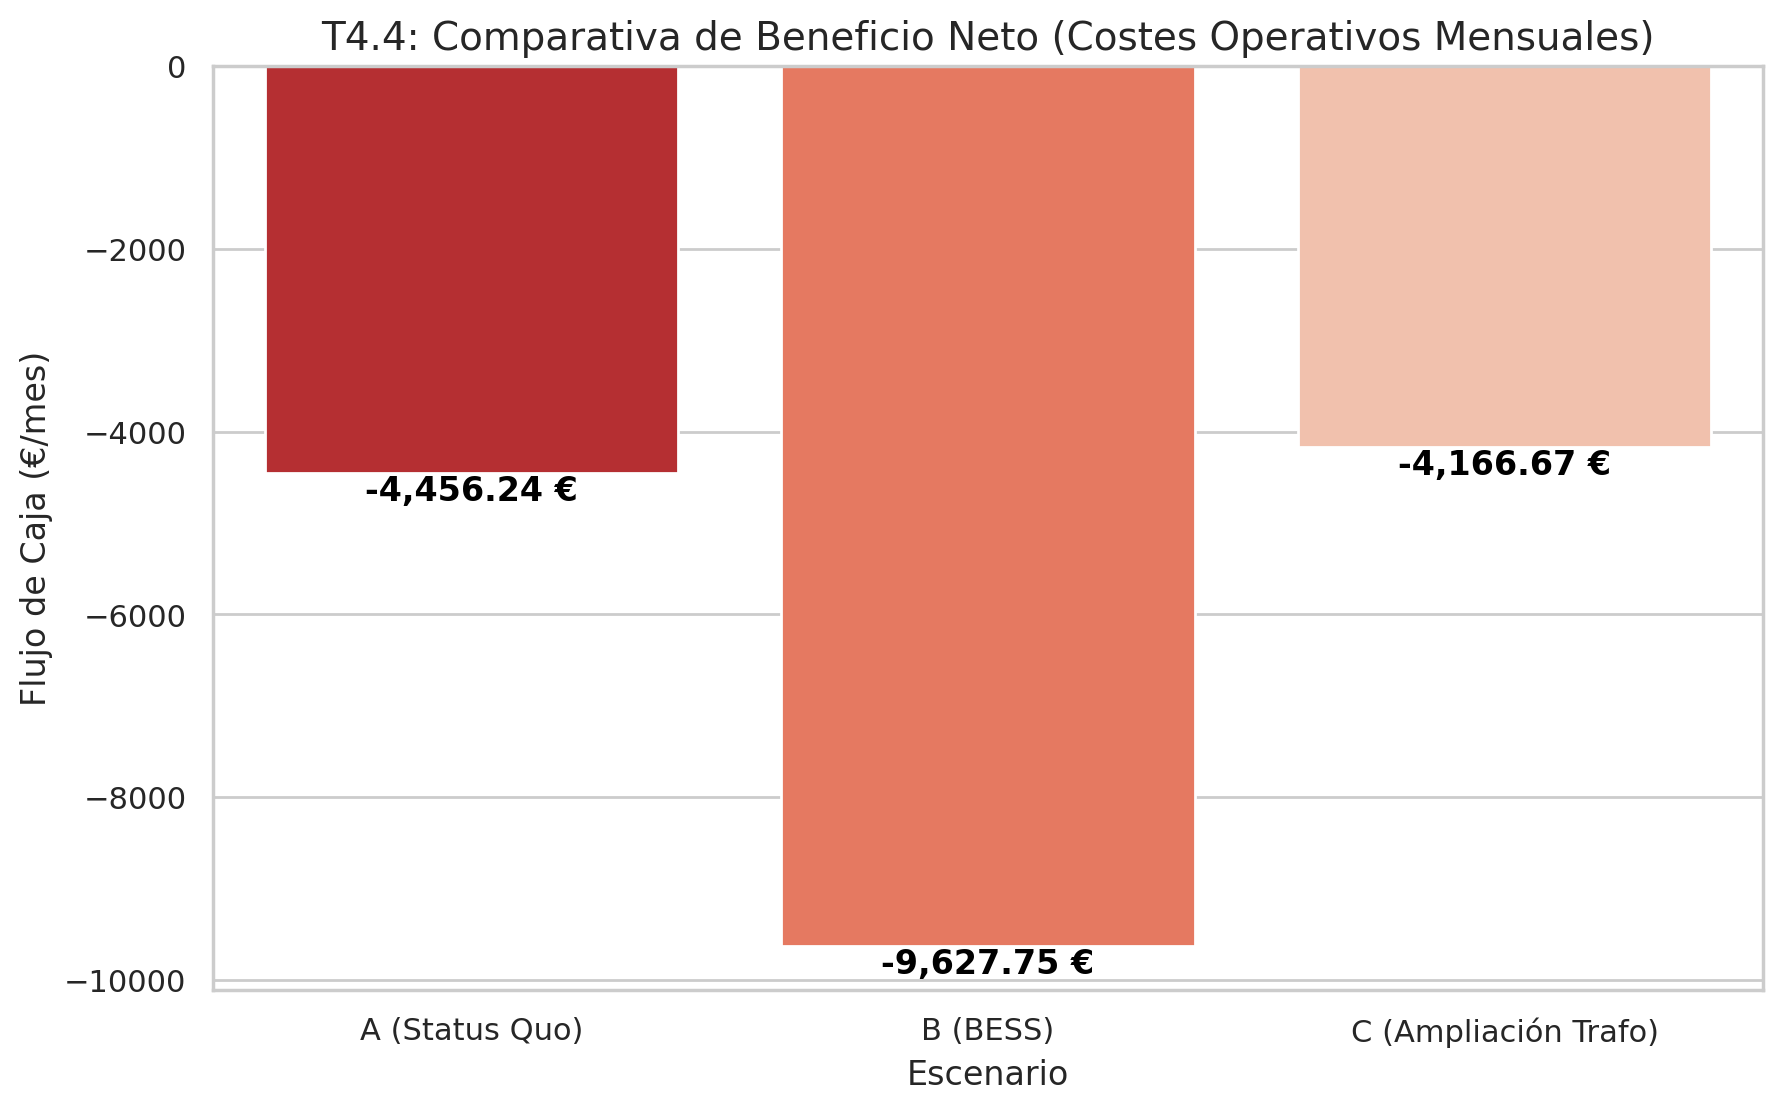

--- TABLA DE DECISIÓN ESTRATÉGICA ---
           Escenario  Beneficio Neto Medio (€/mes) SLA Garantizado (%) Resiliencia (Test Estrés)
      A (Status Quo)                  -4456.240000               < 95%                      Nula
            B (BESS)                  -9627.750000                 99%     Baja (Quiebra a +10%)
C (Ampliación Trafo)                  -4166.666667                100%      Alta (Absorbe picos)


In [37]:
# 1. Recopilamos los datos reales de tus cálculos anteriores
coste_A = -4456.24  # Status Quo: Solo multas
coste_B = -(9495.25 + 132.50)  # BESS: Alquiler + multas residuales
coste_C = -(50000 / 12)  # Ampliación: 50.000€ anuales entre 12 meses

# 2. Creamos la tabla de decisión
datos_decision = {
    'Escenario': ['A (Status Quo)', 'B (BESS)', 'C (Ampliación Trafo)'],
    'Beneficio Neto Medio (€/mes)': [coste_A, coste_B, coste_C],
    'SLA Garantizado (%)': ['< 95%', '99%', '100%'],
    'Resiliencia (Test Estrés)': ['Nula', 'Baja (Quiebra a +10%)', 'Alta (Absorbe picos)']
}
df_decision = pd.DataFrame(datos_decision)

# 3. Visualización
plt.figure(figsize=(10, 6))
sns.barplot(x='Escenario', y='Beneficio Neto Medio (€/mes)', hue='Escenario', data=df_decision, palette='Reds_r', legend=False)

plt.title('T4.4: Comparativa de Beneficio Neto (Costes Operativos Mensuales)', fontsize=14)
plt.ylabel('Flujo de Caja (€/mes)', fontsize=12)
plt.axhline(0, color='black', linewidth=1)

# Añadimos los valores sobre las barras
for i, val in enumerate([coste_A, coste_B, coste_C]):
    plt.text(i, val - 300, f'{val:,.2f} €', horizontalalignment='center', color='black', weight='bold')

plt.show()

# 4. Imprimimos la tabla
print("--- TABLA DE DECISIÓN ESTRATÉGICA ---")
print(df_decision.to_string(index=False))

### T4.4.1. Habilidad IA

El uso del BESS para 'Peak Shaving' exige someter a las baterías de litio a descargas de alta potencia de forma recurrente, lo que acelera el estrés térmico y acorta drásticamente sus ciclos de vida útil.
Riesgo financiero: Si la capacidad nominal ($C$) del BESS cae un 20% por degradación, nuestro escudo perderá más de 75 kW de potencia de inyección. Al perder esa capacidad, los picos de la hora punta volverán a golpear al transformador, provocando cortes diarios. El riesgo financiero es crítico: la empresa acabaría pagando el altísimo coste fijo mensual del alquiler del BESS (~9.500 €/mes) y, simultáneamente, pagando multas por Energía No Servida.

### T4.4.2. Tu veredicto

Mi veredicto personal avogaría por las baterias, si la economía nos permise asumir la baja de ingresos. Pues pese a ser una decisión que va en contra de los intereses directos del inversor promedio (que solo busca sacar beneficio de sus inversiones), creo que tiene una serie de aspectos positivos que pueden compensar esa baja y que cuyo estudio podría desvelar hasta una viabiliad:
- Una mejor imagen como empresa viable y segura puede atraer clientes y accionistas nuevos.
- Se evita difulcas con sanciones o regulaciones.
- Puede ser una puesta a futuro por tecnologías que aun tienen mucho desarrollo por delante.